# ElasticNet Benchmark — RAW vs SCALED (Separate Analyses + Plots)

This notebook runs the full analysis **twice**:

1. **RAW** (original model outputs)
2. **SCALED** (per-sample min–max scaling of `true` and `predicted` separately, scTranslator-style)

It produces four plot files:

- `elasticnet_metrics_raw.png`
- `elasticnet_detailed_metrics_raw.png`
- `elasticnet_metrics_scaled.png`
- `elasticnet_detailed_metrics_scaled.png`

**Input expected:** an HDF5 file named `enet_full_results.h5` in the current working directory (or set `H5_PATH` below).


In [36]:
# 0) Imports
import joblib  # imported in scripts; not required for metrics but kept for parity
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path


In [37]:
# 1) Config
H5_PATH = Path("enet_all_results.h5")  # change if needed

OUT_METRICS_RAW = Path("elasticnet_metrics_raw.png")
OUT_DETAILED_RAW = Path("elasticnet_detailed_metrics_raw.png")

OUT_METRICS_SCALED = Path("elasticnet_metrics_scaled.png")
OUT_DETAILED_SCALED = Path("elasticnet_detailed_metrics_scaled.png")

if not H5_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {H5_PATH.resolve()} — place 'elasticnet_results.h5' next to this notebook or update H5_PATH."
    )


## 2) Load the HDF5 into one long DataFrame (`combined_df`)

Expected columns:
- `protein`
- `LOO sample`
- `true`
- `predicted`


In [38]:
# 2a) Read all protein tables and build a long DataFrame
rows = []

with pd.HDFStore(H5_PATH, mode="r") as store:
    keys = store.keys()
    print(f"Found {len(keys)} protein keys in HDF5")

    for key in keys:
        protein_name = key.strip("/")
        t = store[key].copy()

        # Required columns check (matches what the scripts assume)
        req = {"LOO sample", "true", "predicted"}
        missing = req - set(t.columns)
        if missing:
            raise ValueError(
                f"Key '{key}' is missing required columns: {sorted(missing)}. Found: {list(t.columns)}"
            )

        tmp = t[["LOO sample", "true", "predicted"]].copy()
        tmp["protein"] = protein_name
        rows.append(tmp)

combined_df = pd.concat(rows, ignore_index=True)
combined_df = combined_df[["protein", "LOO sample", "true", "predicted"]]

print("combined_df shape:", combined_df.shape)
combined_df.head()


Found 5113 protein keys in HDF5
combined_df shape: (1886697, 4)


,protein,LOO sample,true,predicted
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651
1,A2M,SH4_SKIN,1.642186,0.308402
2,A2M,AU565_BREAST,-1.129114,-0.899868
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243
4,A2M,CAL51_BREAST,0.274652,0.275565


In [39]:
# 2b) Ensure numeric (coerce non-numeric to NaN)
df = combined_df.copy()
df["true"] = pd.to_numeric(df["true"], errors="coerce")
df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")

print("NaNs after coercion:")
print("  true     :", int(df["true"].isna().sum()))
print("  predicted:", int(df["predicted"].isna().sum()))


NaNs after coercion:
  true     : 0
  predicted: 0


## 3) Build RAW matrices (samples × proteins)

In [40]:
# 3a) RAW pivot matrices
GT_raw = df.pivot(index="LOO sample", columns="protein", values="true")
PRED_raw = df.pivot(index="LOO sample", columns="protein", values="predicted")

print("RAW shapes:")
print("  GT_raw  :", GT_raw.shape)
print("  PRED_raw:", PRED_raw.shape)

assert list(GT_raw.index) == list(PRED_raw.index), "Sample indices don't match!"
assert list(GT_raw.columns) == list(PRED_raw.columns), "Protein columns don't match!"


RAW shapes:
  GT_raw  : (369, 5113)
  PRED_raw: (369, 5113)


## 4) Build SCALED matrices (per-sample min–max scaling, true/pred separately)

In [41]:
# 4a) Scaling function (scTranslator-style)
EPS = 1e-8  # lower bound in target range

def normalization(x: pd.Series, low: float = EPS, high: float = 1.0) -> pd.Series:
    xmin = x.min(skipna=True)
    xmax = x.max(skipna=True)
    if pd.isna(xmin) or pd.isna(xmax):
        return pd.Series(np.nan, index=x.index, dtype="float64")
    if xmax == xmin:
        return pd.Series(low, index=x.index, dtype="float64")
    return low + (x - xmin) / (xmax - xmin) * (high - low)


In [42]:
# 4b) Apply scaling per sample, separately for true and predicted
df["true_mm"] = df.groupby("LOO sample", observed=True)["true"].transform(normalization)
df["pred_mm"] = df.groupby("LOO sample", observed=True)["predicted"].transform(normalization)

df["true_mm"] = df["true_mm"].clip(lower=EPS, upper=1.0)
df["pred_mm"] = df["pred_mm"].clip(lower=EPS, upper=1.0)

print("Ranges after scaling:")
print("  true_mm :", float(np.nanmin(df["true_mm"])), "→", float(np.nanmax(df["true_mm"])))
print("  pred_mm :", float(np.nanmin(df["pred_mm"])), "→", float(np.nanmax(df["pred_mm"])))


Ranges after scaling:
  true_mm : 1e-08 → 1.0
  pred_mm : 1e-08 → 1.0


In [43]:
# 4c) SCALED pivot matrices
GT_scaled = df.pivot(index="LOO sample", columns="protein", values="true_mm")
PRED_scaled = df.pivot(index="LOO sample", columns="protein", values="pred_mm")

print("SCALED shapes:")
print("  GT_scaled  :", GT_scaled.shape)
print("  PRED_scaled:", PRED_scaled.shape)

assert list(GT_scaled.index) == list(PRED_scaled.index), "Sample indices don't match!"
assert list(GT_scaled.columns) == list(PRED_scaled.columns), "Protein columns don't match!"


SCALED shapes:
  GT_scaled  : (369, 5113)
  PRED_scaled: (369, 5113)


## 5) Metric functions (same as scripts)

In [44]:
def cosine_similarity(y_true, y_pred, eps=1e-8):
    dot_product = np.dot(y_true, y_pred)
    norm_true = np.linalg.norm(y_true)
    norm_pred = np.linalg.norm(y_pred)
    return dot_product / max(norm_true * norm_pred, eps)

def pearson_correlation(y_true, y_pred):
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return np.corrcoef(y_true, y_pred)[0, 1]

def spearman_correlation(y_true, y_pred):
    return stats.spearmanr(y_true, y_pred)[0]

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


## 6) Helper functions to compute metrics and generate plots

In [45]:
def compute_mean_metrics(ground_truth, predictions):
    metrics_per_sample = {
        "MSE": [],
        "RMSE": [],
        "MAE": [],
        "Pearson": [],
        "Spearman": [],
        "Cosine": [],
    }

    for sample in predictions.index.tolist():
        y_true = ground_truth.loc[sample].values.astype(float)
        y_pred = predictions.loc[sample].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 0:
            metrics_per_sample["MSE"].append(mse(y_true_clean, y_pred_clean))
            metrics_per_sample["RMSE"].append(rmse(y_true_clean, y_pred_clean))
            metrics_per_sample["MAE"].append(mae(y_true_clean, y_pred_clean))
            metrics_per_sample["Pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))
            metrics_per_sample["Spearman"].append(spearman_correlation(y_true_clean, y_pred_clean))
            metrics_per_sample["Cosine"].append(cosine_similarity(y_true_clean, y_pred_clean))

    return {k: np.nanmean(v) for k, v in metrics_per_sample.items()}

def compute_detailed_tables(ground_truth, predictions):
    # Per-cell metrics
    per_cell = {"sample": [], "cosine": [], "pearson": [], "mse": [], "mae": []}
    samples = predictions.index.tolist()
    proteins = predictions.columns.tolist()

    for sample in samples:
        y_true = ground_truth.loc[sample].values.astype(float)
        y_pred = predictions.loc[sample].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 0:
            per_cell["sample"].append(sample)
            per_cell["cosine"].append(cosine_similarity(y_true_clean, y_pred_clean))
            per_cell["pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))
            per_cell["mse"].append(mse(y_true_clean, y_pred_clean))
            per_cell["mae"].append(mae(y_true_clean, y_pred_clean))

    per_cell_df = pd.DataFrame(per_cell)

    # Per-protein PCC across samples
    per_protein = {"protein": [], "pearson": []}
    for protein in proteins:
        y_true = ground_truth[protein].values.astype(float)
        y_pred = predictions[protein].values.astype(float)

        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]

        if len(y_true_clean) > 1:
            per_protein["protein"].append(protein)
            per_protein["pearson"].append(pearson_correlation(y_true_clean, y_pred_clean))

    per_protein_df = pd.DataFrame(per_protein).sort_values("pearson", ascending=False)
    top_10 = per_protein_df.head(10)
    bottom_10 = per_protein_df.tail(10)

    return per_cell_df, per_protein_df, top_10, bottom_10

def plot_overall_bar(mean_metrics, title, out_path):
    plt.style.use("seaborn-v0_8-whitegrid")

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.patch.set_facecolor("#F8F9FA")

    fig.suptitle(title, fontsize=20, fontweight="bold", color="#2C3E50", y=0.98)

    colors = ["#E74C3C", "#E67E22", "#F39C12", "#27AE60", "#2980B9", "#9B59B6"]
    plots = [
        ("Mean Squared Error", "MSE", mean_metrics["MSE"], colors[0]),
        ("Root MSE", "RMSE", mean_metrics["RMSE"], colors[1]),
        ("Mean Absolute Error", "MAE", mean_metrics["MAE"], colors[2]),
        ("Pearson Correlation", "PCC", mean_metrics["Pearson"], colors[3]),
        ("Spearman Correlation", "SCC", mean_metrics["Spearman"], colors[4]),
        ("Cosine Similarity", "COS", mean_metrics["Cosine"], colors[5]),
    ]

    for idx, (t, ylabel, value, color) in enumerate(plots):
        row, col = divmod(idx, 3)
        ax = axes[row, col]
        ax.set_facecolor("#FFFFFF")

        bar = ax.bar(["ElasticNet"], [value], color=color, width=0.6,
                     edgecolor="#2C3E50", linewidth=2, alpha=0.9)

        ax.bar(["ElasticNet"], [value], color="gray", width=0.6, alpha=0.1,
               bottom=-value * 0.02 if value > 0 else value * 0.02)

        for rect in bar:
            height = rect.get_height()
            ax.annotate(
                f"{value:.4f}",
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=14,
                fontweight="bold",
                color="#2C3E50",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=color, alpha=0.8),
            )

        ax.set_title(t, fontsize=14, fontweight="bold", color="#2C3E50", pad=15)
        ax.set_ylabel(ylabel, fontsize=12, fontweight="bold", color="#2C3E50")

        if value >= 0:
            ax.set_ylim(0, value * 1.35 if value > 0 else 1)
        else:
            ax.set_ylim(value * 1.35, abs(value) * 0.35)

        ax.tick_params(axis="x", labelsize=12, colors="#2C3E50")
        ax.tick_params(axis="y", labelsize=10, colors="#7F8C8D")
        ax.yaxis.grid(True, linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_color("#BDC3C7")
            spine.set_linewidth(1.5)
        ax.spines["bottom"].set_visible(False)

    plt.tight_layout(rect=[0, 0.02, 1, 0.95])
    plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"Saved: {out_path}")
    plt.show()

def plot_detailed(per_cell_df, per_protein_df, top_10, bottom_10, title, out_path):
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(
        2, 3,
        width_ratios=[1, 1, 1],
        height_ratios=[1, 1],
        hspace=0.3,
        wspace=0.3,
    )

    cell_cosine_color = "#5DADE2"
    cell_pcc_color = "#F5B041"
    cell_mse_color = "#58D68D"
    protein_pcc_color = "#AF7AC5"

    # 1) Per-cell cosine
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.hist(per_cell_df["cosine"], bins=30, color=cell_cosine_color, edgecolor="black", alpha=0.8)
    mean_cosine = per_cell_df["cosine"].mean()
    ax1.axvline(mean_cosine, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_cosine:.3f}")
    ax1.set_xlabel("Cosine Similarity", fontsize=10)
    ax1.set_ylabel("Count", fontsize=10)
    ax1.set_title("Per-Cell Cosine Similarity", fontsize=12, fontweight="bold")
    ax1.legend(loc="upper right")

    # 2) Per-cell PCC
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.hist(per_cell_df["pearson"], bins=30, color=cell_pcc_color, edgecolor="black", alpha=0.8)
    mean_pcc = per_cell_df["pearson"].mean()
    ax2.axvline(mean_pcc, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_pcc:.3f}")
    ax2.set_xlabel("Pearson Correlation", fontsize=10)
    ax2.set_ylabel("Count", fontsize=10)
    ax2.set_title("Per-Cell PCC", fontsize=12, fontweight="bold")
    ax2.legend(loc="upper right")

    # 3) Per-cell MSE
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.hist(per_cell_df["mse"], bins=30, color=cell_mse_color, edgecolor="black", alpha=0.8)
    mean_mse = per_cell_df["mse"].mean()
    ax3.axvline(mean_mse, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_mse:.4f}")
    ax3.set_xlabel("MSE", fontsize=10)
    ax3.set_ylabel("Count", fontsize=10)
    ax3.set_title("Per-Cell MSE", fontsize=12, fontweight="bold")
    ax3.legend(loc="upper right")

    # 4) Per-protein PCC
    ax4 = fig.add_subplot(gs[1, 0])
    ax4.hist(per_protein_df["pearson"].dropna(), bins=30, color=protein_pcc_color, edgecolor="black", alpha=0.8)
    mean_protein_pcc = per_protein_df["pearson"].mean()
    ax4.axvline(mean_protein_pcc, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_protein_pcc:.3f}")
    ax4.set_xlabel("Pearson Correlation", fontsize=10)
    ax4.set_ylabel("Count", fontsize=10)
    ax4.set_title("Per-Protein PCC (across cells)", fontsize=12, fontweight="bold")
    ax4.legend(loc="upper right")

    # 5) Top/bottom proteins
    ax5 = fig.add_subplot(gs[1, 1])
    top_10_sorted = top_10.sort_values("pearson", ascending=True)
    bottom_10_sorted = bottom_10.sort_values("pearson", ascending=False)
    combined = pd.concat([top_10_sorted, bottom_10_sorted])

    colors = ["#58D68D"] * 10 + ["#E74C3C"] * 10
    y_pos = np.arange(len(combined))
    ax5.barh(y_pos, combined["pearson"].values, color=colors, edgecolor="black", alpha=0.8)
    ax5.set_yticks(y_pos)
    ax5.set_yticklabels(combined["protein"].values, fontsize=8)
    ax5.axvline(0, color="red", linestyle="-", linewidth=1)
    ax5.set_xlabel("PCC", fontsize=10)
    ax5.set_title("Top 10 / Bottom 10 Proteins by PCC", fontsize=12, fontweight="bold")

    # 6) Summary panel
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.axis("off")

    n_cells = len(per_cell_df)
    n_proteins = len(per_protein_df)
    positive_pcc_count = (per_protein_df["pearson"] > 0).sum()
    positive_pcc_pct = positive_pcc_count / n_proteins * 100 if n_proteins else np.nan
    high_pcc_03 = (per_protein_df["pearson"] > 0.3).sum()
    high_pcc_05 = (per_protein_df["pearson"] > 0.5).sum()

    summary_text = f"""Summary Statistics
{'='*40}

Per-Cell (n={n_cells}):
Cosine:
  Mean: {per_cell_df['cosine'].mean():.4f} +/- {per_cell_df['cosine'].std():.4f}
  Min:  {per_cell_df['cosine'].min():.4f}
  Max:  {per_cell_df['cosine'].max():.4f}

Pearson:
  Mean: {per_cell_df['pearson'].mean():.4f} +/- {per_cell_df['pearson'].std():.4f}
  Min:  {per_cell_df['pearson'].min():.4f}
  Max:  {per_cell_df['pearson'].max():.4f}

MSE:
  Mean: {per_cell_df['mse'].mean():.4f} +/- {per_cell_df['mse'].std():.4f}

MAE:
  Mean: {per_cell_df['mae'].mean():.4f} +/- {per_cell_df['mae'].std():.4f}

Per-Protein PCC (n={n_proteins}):
  Mean: {per_protein_df['pearson'].mean():.4f} +/- {per_protein_df['pearson'].std():.4f}
  Positive: {positive_pcc_count} ({positive_pcc_pct:.1f}%)
  > 0.3:    {high_pcc_03} ({(high_pcc_03/n_proteins*100) if n_proteins else np.nan:.1f}%)
  > 0.5:    {high_pcc_05} ({(high_pcc_05/n_proteins*100) if n_proteins else np.nan:.1f}%)
"""

    ax6.text(
        0.05, 0.95,
        summary_text,
        transform=ax6.transAxes,
        fontsize=9,
        verticalalignment="top",
        fontfamily="monospace",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    )

    fig.suptitle(title, fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.show()


# RAW analysis (original scale)

In [46]:
# 7) RAW: compute mean metrics
mean_metrics_raw = compute_mean_metrics(GT_raw, PRED_raw)
print("Mean Metrics (RAW):")
for k, v in mean_metrics_raw.items():
    print(f"  {k:8s}: {v:.6f}")


Mean Metrics (RAW):
  MSE     : 0.349150
  RMSE    : 0.579322
  MAE     : 0.444333
  Pearson : 0.668077
  Spearman: 0.569050
  Cosine  : 0.656606


Saved: elasticnet_metrics_raw.png


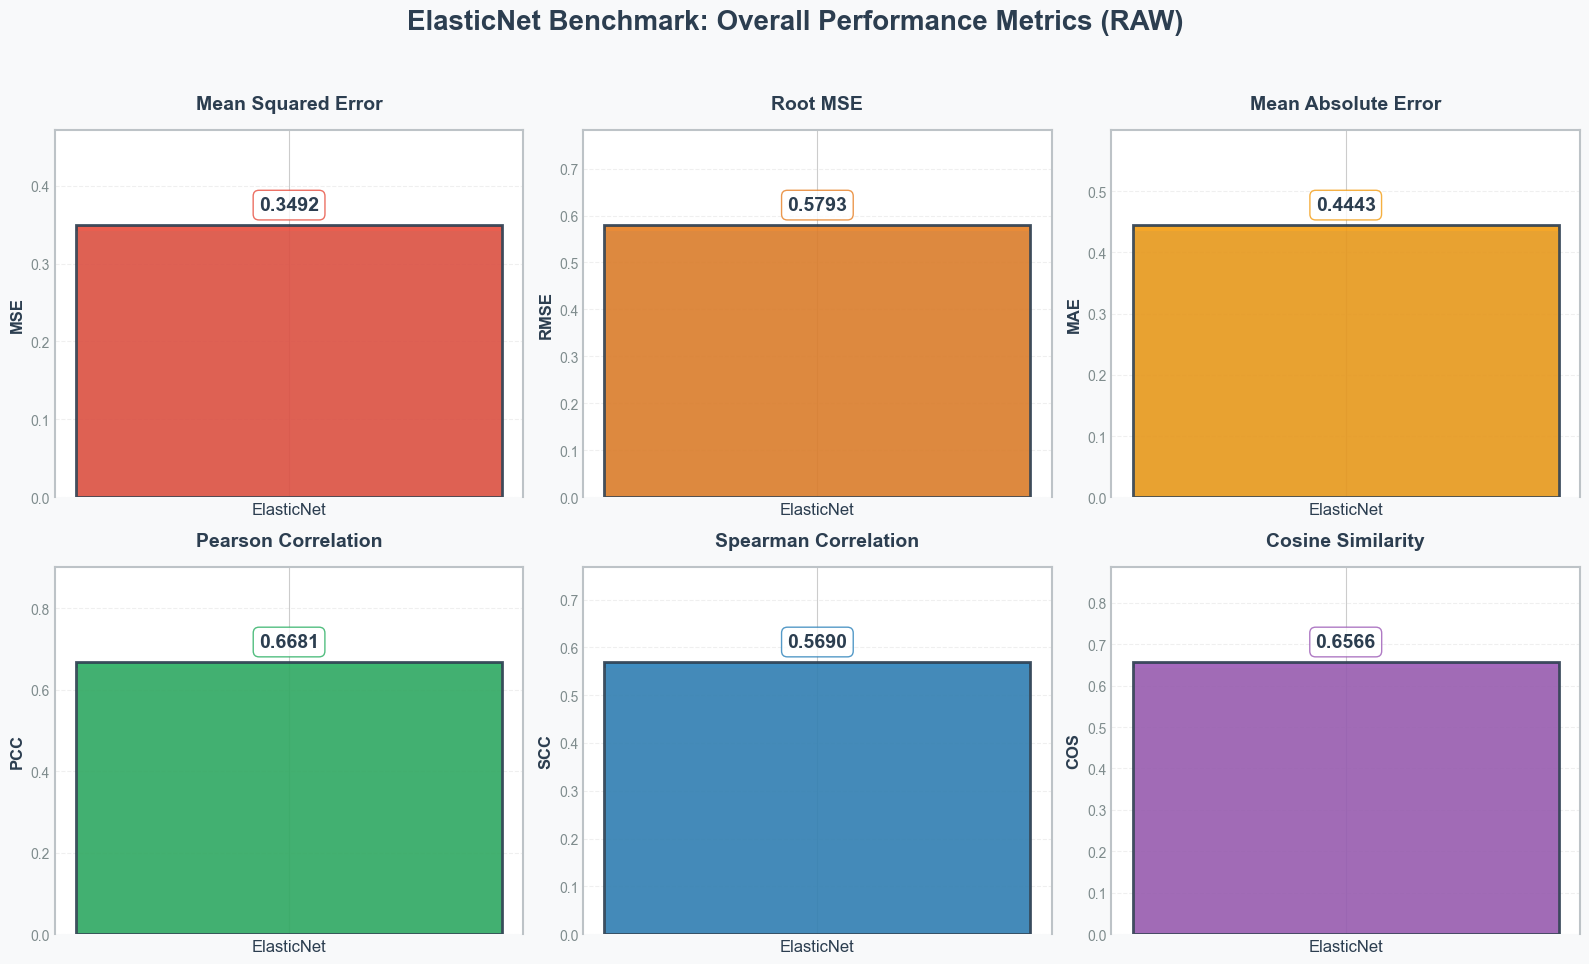

In [47]:
# 8) RAW: overall bar chart
plot_overall_bar(
    mean_metrics_raw,
    title="ElasticNet Benchmark: Overall Performance Metrics (RAW)",
    out_path=OUT_METRICS_RAW
)


In [48]:
# 9) RAW: detailed tables
per_cell_raw, per_protein_raw, top10_raw, bottom10_raw = compute_detailed_tables(GT_raw, PRED_raw)

print("RAW detailed tables:")
print("  cells   :", len(per_cell_raw))
print("  proteins:", len(per_protein_raw))

display(per_cell_raw.head())
display(per_protein_raw.head(10))


RAW detailed tables:
  cells   : 369
  proteins: 5113


,sample,cosine,pearson,mse,mae
0,22RV1_PROSTATE,0.638976,0.636914,0.496394,0.569589
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.802465,0.797503,0.342388,0.453077
2,769P_KIDNEY,0.743420,0.769340,0.271616,0.382869
3,786O_KIDNEY,0.655691,0.652421,0.350048,0.472970
4,8305C_THYROID,0.619457,0.628299,0.464801,0.541696


,protein,pearson
2016,IGF2BP1,0.908862
433,BASP1,0.906439
2346,MAGEA4,0.898980
2363,MAP1B,0.885239
1719,GNG12,0.885098
924,CORO1A,0.884077
4526,TJP2,0.879913
2233,LCP1,0.879216
1843,HCLS1,0.878749
3655,RBM47,0.877860


C:\Users\hp\AppData\Local\Temp\ipykernel_12792\773615424.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: elasticnet_detailed_metrics_raw.png


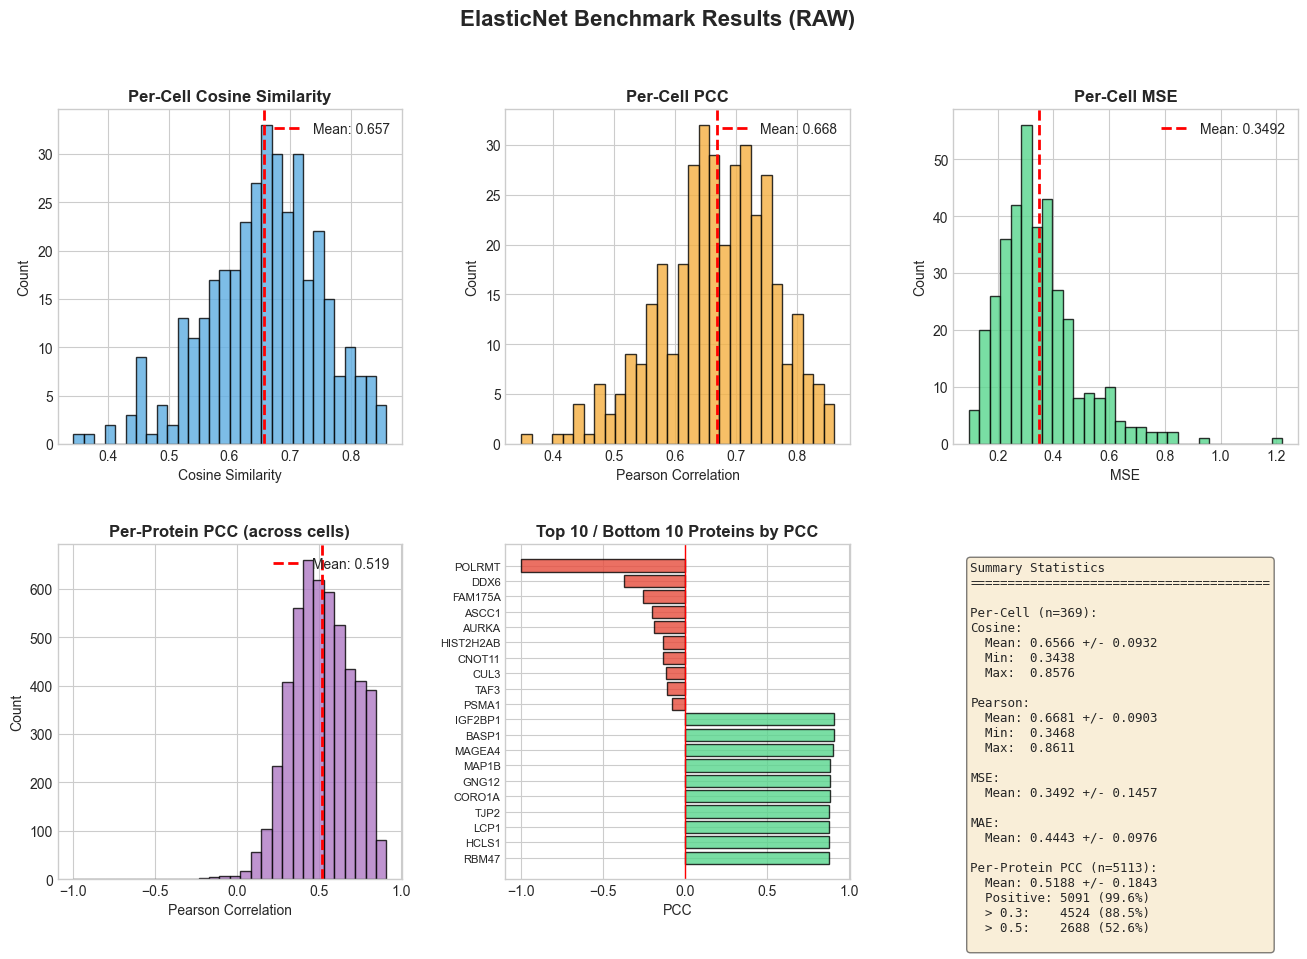

In [49]:
# 10) RAW: detailed visualization
plot_detailed(
    per_cell_raw,
    per_protein_raw,
    top10_raw,
    bottom10_raw,
    title="ElasticNet Benchmark Results (RAW)",
    out_path=OUT_DETAILED_RAW
)


# SCALED analysis (per-sample min–max)

In [50]:
# 11) SCALED: compute mean metrics
mean_metrics_scaled = compute_mean_metrics(GT_scaled, PRED_scaled)
print("Mean Metrics (SCALED per-sample min–max):")
for k, v in mean_metrics_scaled.items():
    print(f"  {k:8s}: {v:.6f}")


Mean Metrics (SCALED per-sample min–max):
  MSE     : 0.016814
  RMSE    : 0.115082
  MAE     : 0.100603
  Pearson : 0.668077
  Spearman: 0.569050
  Cosine  : 0.988667


Saved: elasticnet_metrics_scaled.png


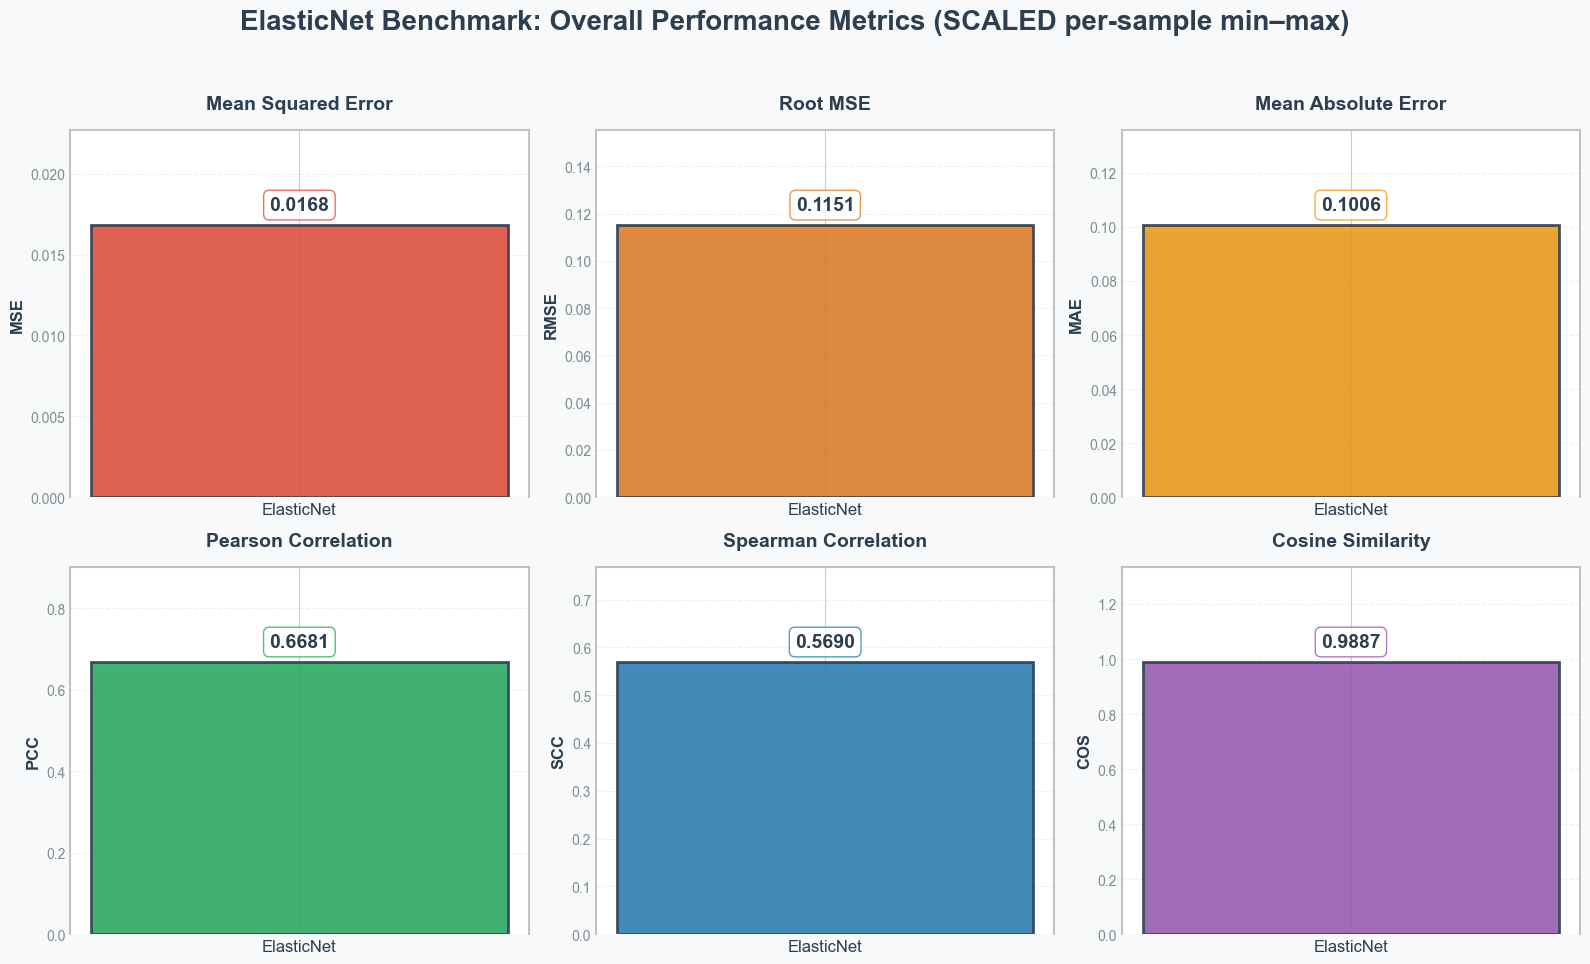

In [51]:
# 12) SCALED: overall bar chart
plot_overall_bar(
    mean_metrics_scaled,
    title="ElasticNet Benchmark: Overall Performance Metrics (SCALED per-sample min–max)",
    out_path=OUT_METRICS_SCALED
)


In [52]:
# 13) SCALED: detailed tables
per_cell_scaled, per_protein_scaled, top10_scaled, bottom10_scaled = compute_detailed_tables(GT_scaled, PRED_scaled)

print("SCALED detailed tables:")
print("  cells   :", len(per_cell_scaled))
print("  proteins:", len(per_protein_scaled))

display(per_cell_scaled.head())
display(per_protein_scaled.head(10))


SCALED detailed tables:
  cells   : 369
  proteins: 5113


,sample,cosine,pearson,mse,mae
0,22RV1_PROSTATE,0.990179,0.636914,0.006625,0.065014
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.988982,0.797503,0.006213,0.064663
2,769P_KIDNEY,0.990764,0.769340,0.007117,0.070091
3,786O_KIDNEY,0.986676,0.652421,0.010046,0.082553
4,8305C_THYROID,0.984207,0.628299,0.006866,0.065935


,protein,pearson
433,BASP1,0.853678
1386,EPCAM,0.805745
3898,S100A14,0.793624
2346,MAGEA4,0.791338
4402,TACSTD2,0.789501
4306,ST14,0.775901
565,CA2,0.774254
4004,SERPINB5,0.774187
3100,PDLIM4,0.773463
2016,IGF2BP1,0.772038


C:\Users\hp\AppData\Local\Temp\ipykernel_12792\773615424.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: elasticnet_detailed_metrics_scaled.png


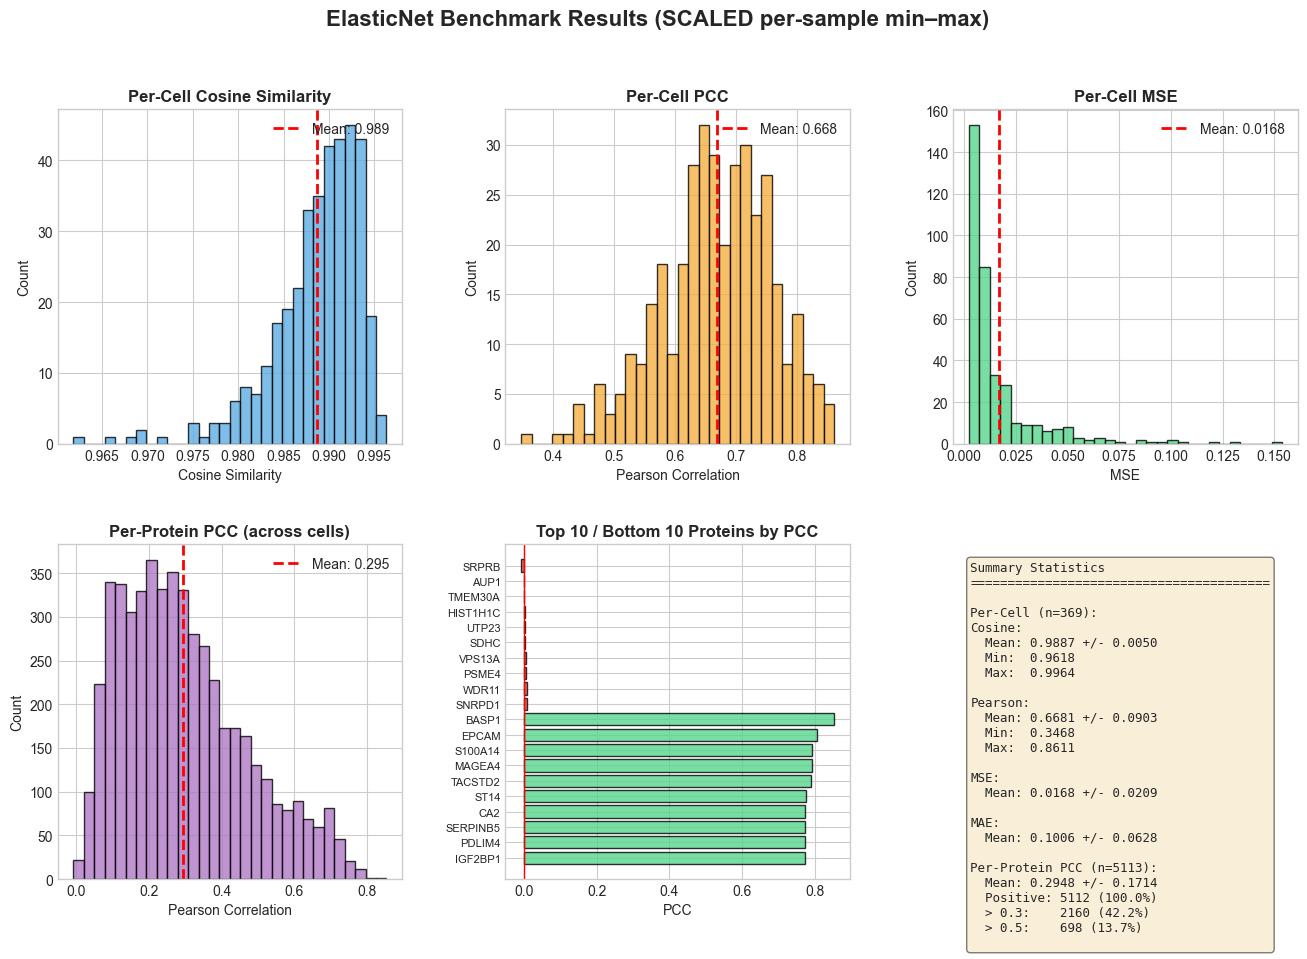

In [53]:
# 14) SCALED: detailed visualization
plot_detailed(
    per_cell_scaled,
    per_protein_scaled,
    top10_scaled,
    bottom10_scaled,
    title="ElasticNet Benchmark Results (SCALED per-sample min–max)",
    out_path=OUT_DETAILED_SCALED
)


## Optional quick check: correlations should match (almost) exactly

Pearson/Spearman are scale-invariant (with positive scaling), so RAW vs SCALED should match except for constant-vector/NaN edge cases.


In [54]:
print("Mean Pearson RAW   :", float(mean_metrics_raw["Pearson"]))
print("Mean Pearson SCALED:", float(mean_metrics_scaled["Pearson"]))
print("Mean Spearman RAW  :", float(mean_metrics_raw["Spearman"]))
print("Mean Spearman SCALED:", float(mean_metrics_scaled["Spearman"]))


Mean Pearson RAW   : 0.6680773220567542
Mean Pearson SCALED: 0.6680773220567542
Mean Spearman RAW  : 0.5690496986218593
Mean Spearman SCALED: 0.5690496986218593


## scTranslator vs ElasticNet Comparison

We now compare the results of ElasticNet against the model scTranslator. scTranslator has three publically available checkpoints: 10k, 160k, and 2M representing the size of the pre-training. The comparison will re-run the same analysis as we have done above on ElasticNet on the three scTranslator models then we will compare the distributions of the predicted protein abundance of the two models ElasticNet and scTranslator


Below we load the predictions for protein abundance of the three models into a data frame and make sure all cells and proteins are aligned with the Ground Truth scaled we have defined before

In [55]:
# 1b) Load scTranslator predictions (bundled with names/ids)
base_dir = Path(".")
pred_bundle_paths = {
    "2M": base_dir / "sc_predictions_2M.npz",
    "160K": base_dir / "sc_predictions_160K.npz",
    "10K": base_dir / "sc_predictions_10K.npz",
}

bundles = {label: np.load(path) for label, path in pred_bundle_paths.items()}

pred_df_2m = pd.DataFrame(
    bundles["2M"]["predictions"],
    columns=[str(x) for x in bundles["2M"]["protein_names"]],
)
pred_df_160k = pd.DataFrame(
    bundles["160K"]["predictions"],
    columns=[str(x) for x in bundles["160K"]["protein_names"]],
)
pred_df_10k = pd.DataFrame(
    bundles["10K"]["predictions"],
    columns=[str(x) for x in bundles["10K"]["protein_names"]],
)
# 1c) Apply cell names as DataFrame index
pred_df_2m.index = [str(x) for x in bundles["2M"]["cell_names"]]
pred_df_160k.index = [str(x) for x in bundles["160K"]["cell_names"]]
pred_df_10k.index = [str(x) for x in bundles["10K"]["cell_names"]]


#Reindex the order to make suyre
pred_df_2m = pred_df_2m.reindex(index = GT_scaled.index, columns = GT_scaled.columns)
pred_df_160k = pred_df_160k.reindex(index = GT_scaled.index, columns = GT_scaled.columns)
pred_df_10k = pred_df_10k.reindex(index = GT_scaled.index, columns = GT_scaled.columns)

We use the same functions as we have above to compute the mean metrics for all three models of scTranslator then we plot them all side-by-side 

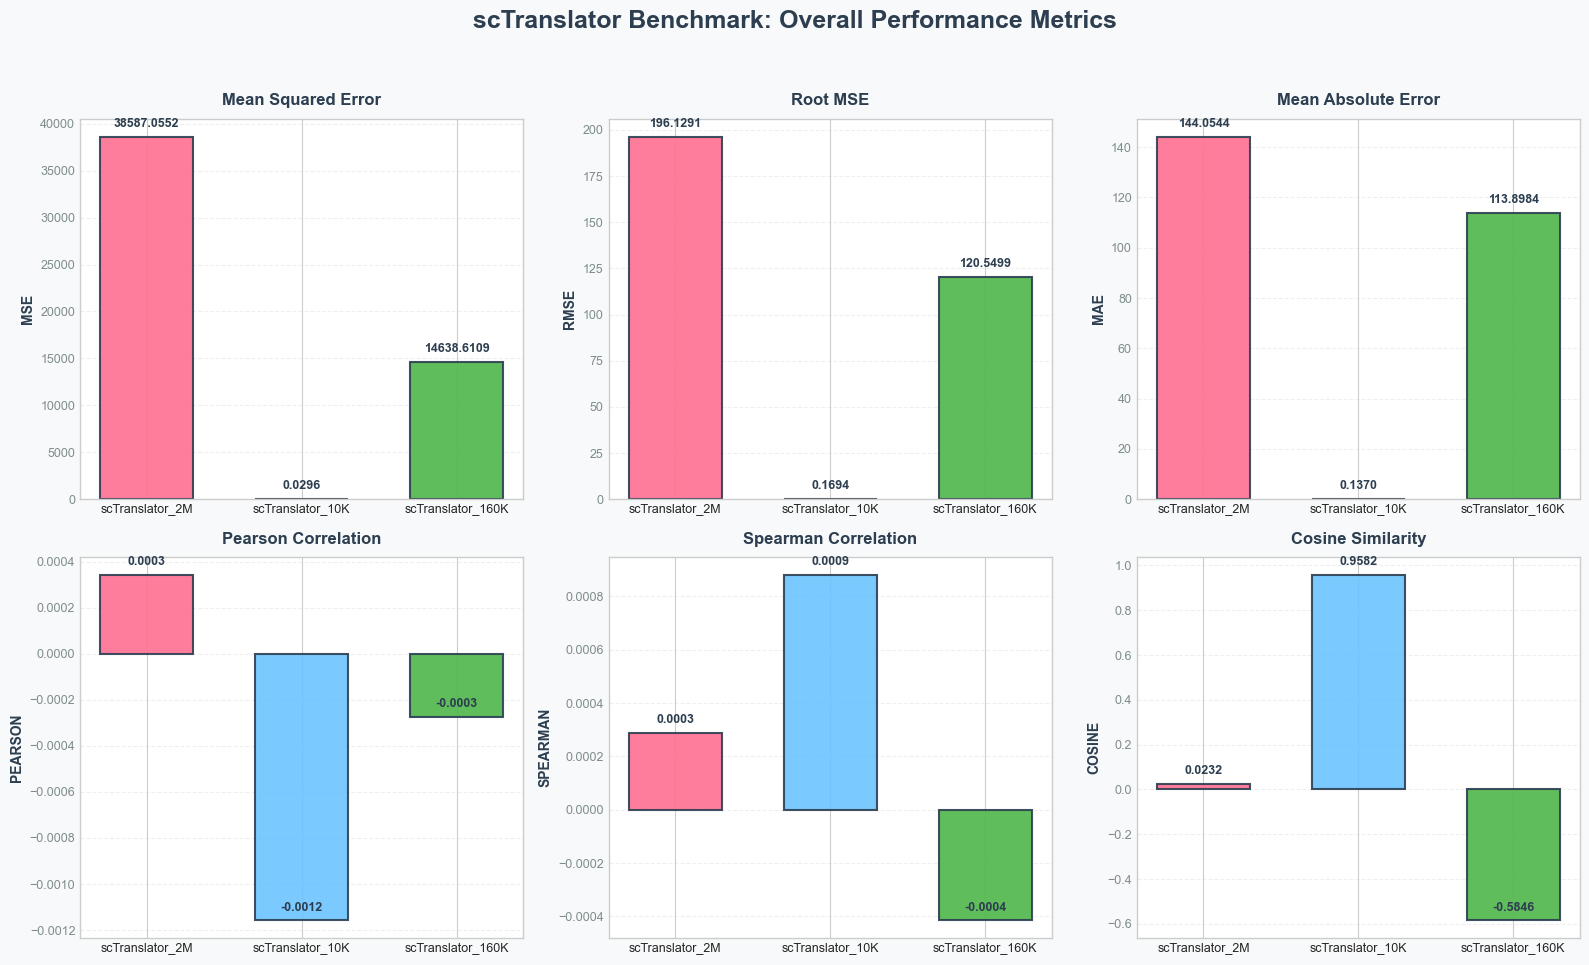

In [56]:
# ---------- compute mean metrics ----------
metrics_2M = compute_mean_metrics(GT_scaled, pred_df_2m)
metrics_10K = compute_mean_metrics(GT_scaled, pred_df_10k)
metrics_160K = compute_mean_metrics(GT_scaled, pred_df_160k)

# ---------- build table for plotting ----------
models = ["scTranslator_2M", "scTranslator_10K", "scTranslator_160K"]
metric_order = [
    ("Mean Squared Error", "MSE"),
    ("Root MSE", "RMSE"),
    ("Mean Absolute Error", "MAE"),
    ("Pearson Correlation", "Pearson"),
    ("Spearman Correlation", "Spearman"),
    ("Cosine Similarity", "Cosine"),
]

metrics_df = pd.DataFrame(
    [metrics_2M, metrics_10K, metrics_160K],
    index=models
)

# ---------- plot ----------
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.patch.set_facecolor("#F8F9FA")
fig.suptitle("scTranslator Benchmark: Overall Performance Metrics",
             fontsize=18, fontweight="bold", color="#2C3E50", y=0.98)

bar_colors = ["#FF6F91", "#6CC4FF", "#4FB64A"]  # pink, blue, green

for idx, (title, key) in enumerate(metric_order):
    row, col = divmod(idx, 3)
    ax = axes[row, col]
    ax.set_facecolor("#FFFFFF")

    values = metrics_df[key].values.astype(float)
    bars = ax.bar(models, values, color=bar_colors, width=0.6,
                  edgecolor="#2C3E50", linewidth=1.5, alpha=0.9)

    # value labels
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.4f}",
                    xy=(b.get_x() + b.get_width()/2, h),
                    xytext=(0, 5),
                    textcoords="offset points",
                    ha="center", va="bottom",
                    fontsize=9, fontweight="bold", color="#2C3E50")

    ax.set_title(title, fontsize=12, fontweight="bold", color="#2C3E50", pad=10)
    ax.set_ylabel(key.upper(), fontsize=10, fontweight="bold", color="#2C3E50")
    ax.tick_params(axis="x", labelsize=9, rotation=0)
    ax.tick_params(axis="y", labelsize=9, colors="#7F8C8D")
    ax.yaxis.grid(True, linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()

#### To get more insight into model-specific performance of scTranslator we now plot metrics for each specific model. The plot above is averaged across samples in the dataset so it says nothing of the distribution of these metrics across cells and moreover across proteins. Thus below we plot histograms of Per-cell MSE, Cosine Similarity and then do the same Per-Protein. Moreover we plot the top 10 and bottom 10 proteins ranked by PCC

Analysis for 10k

10k detailed tables:
  cells   : 369
  proteins: 5112


,sample,cosine,pearson,mse,mae
0,22RV1_PROSTATE,0.958328,-0.061457,0.022682,0.118695
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.953471,-0.014901,0.024226,0.121917
2,769P_KIDNEY,0.954590,0.032387,0.024334,0.123915
3,786O_KIDNEY,0.955240,0.039941,0.028298,0.137323
4,8305C_THYROID,0.953292,0.055025,0.023493,0.120505


,protein,pearson
4442,TBCA,0.360360
693,CD9,0.336713
2200,KTI12,0.320515
3017,PAFAH1B3,0.312388
4593,TNRC6B,0.308993
4778,UBE2N,0.301594
1593,FTO,0.287951
3483,PSPH,0.286030
346,ATE1,0.283959
4330,STMN1,0.282122


C:\Users\hp\AppData\Local\Temp\ipykernel_12792\773615424.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: elasticnet_detailed_metrics_raw.png


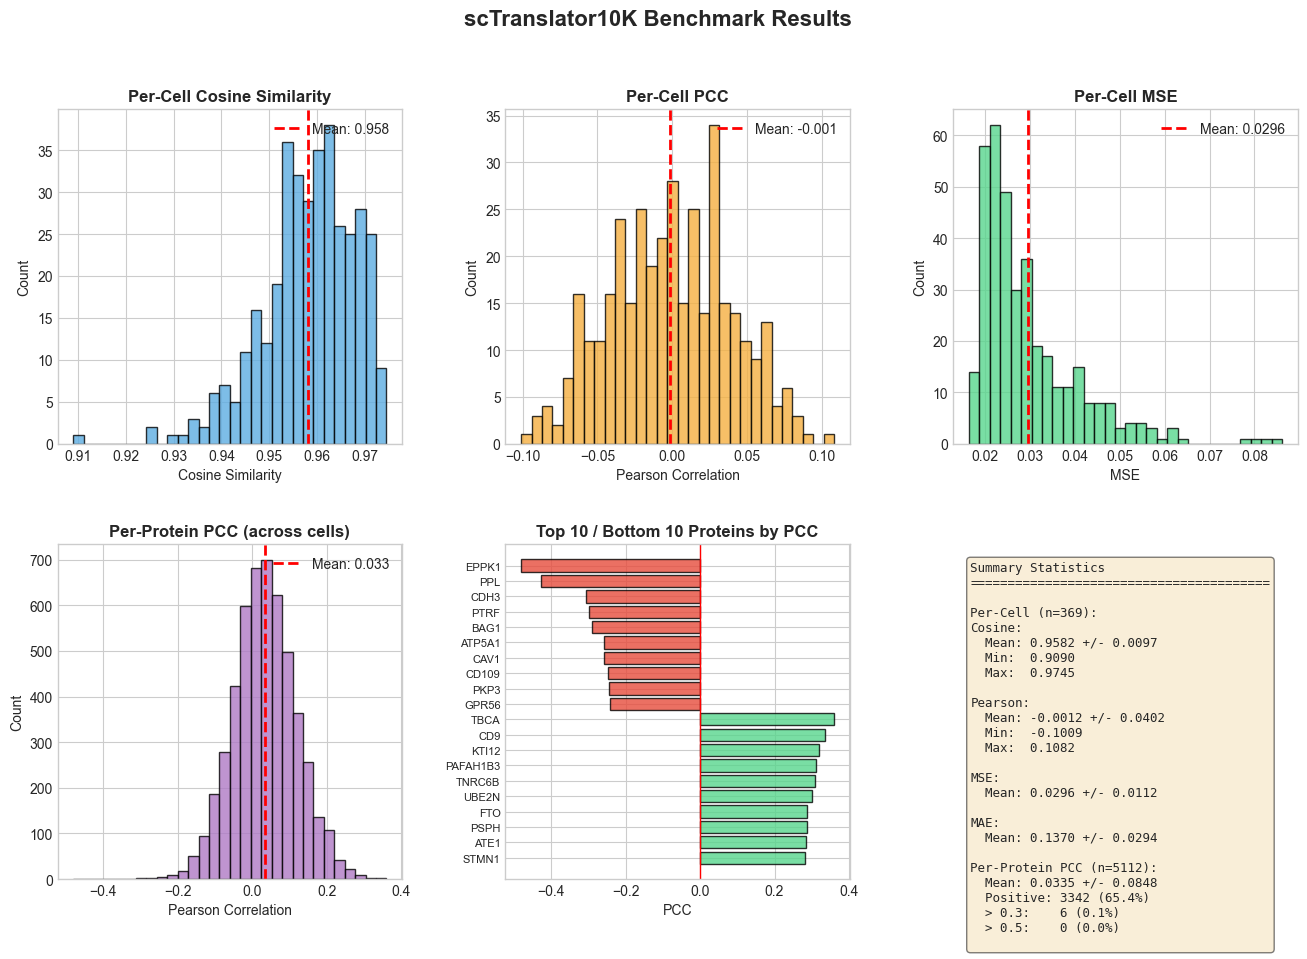

In [57]:
per_cell_10k, per_protein_10k, top10_10k, bottom10_10k = compute_detailed_tables(GT_scaled, pred_df_10k)

print("10k detailed tables:")
print("  cells   :", len(per_cell_10k))
print("  proteins:", len(per_protein_10k))

display(per_cell_10k.head())
display(per_protein_10k.head(10))
plot_detailed(
    per_cell_10k,
    per_protein_10k,
    top10_10k,
    bottom10_10k,
    title="scTranslator10K Benchmark Results",
    out_path=OUT_DETAILED_RAW
)


Analysis for 160k

160k detailed tables:
  cells   : 369
  proteins: 5112


,sample,cosine,pearson,mse,mae
0,22RV1_PROSTATE,-0.584976,0.006553,16053.644228,119.711509
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-0.582838,-0.004124,12335.402035,104.938658
2,769P_KIDNEY,-0.581345,0.001552,12791.539034,106.861139
3,786O_KIDNEY,-0.586105,-0.025385,14031.806621,111.923985
4,8305C_THYROID,-0.580736,-0.001954,14354.122363,113.199426


,protein,pearson
3723,RNASET2,0.259485
2927,NUDT8,0.247183
2606,MRRF,0.243959
2318,LSP1,0.242302
806,CIB1,0.242143
3140,PFN2,0.241027
1505,FAM83H,0.236855
2500,MISP,0.233911
1353,ELF1,0.232107
4305,ST14,0.231272


C:\Users\hp\AppData\Local\Temp\ipykernel_12792\773615424.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: elasticnet_detailed_metrics_raw.png


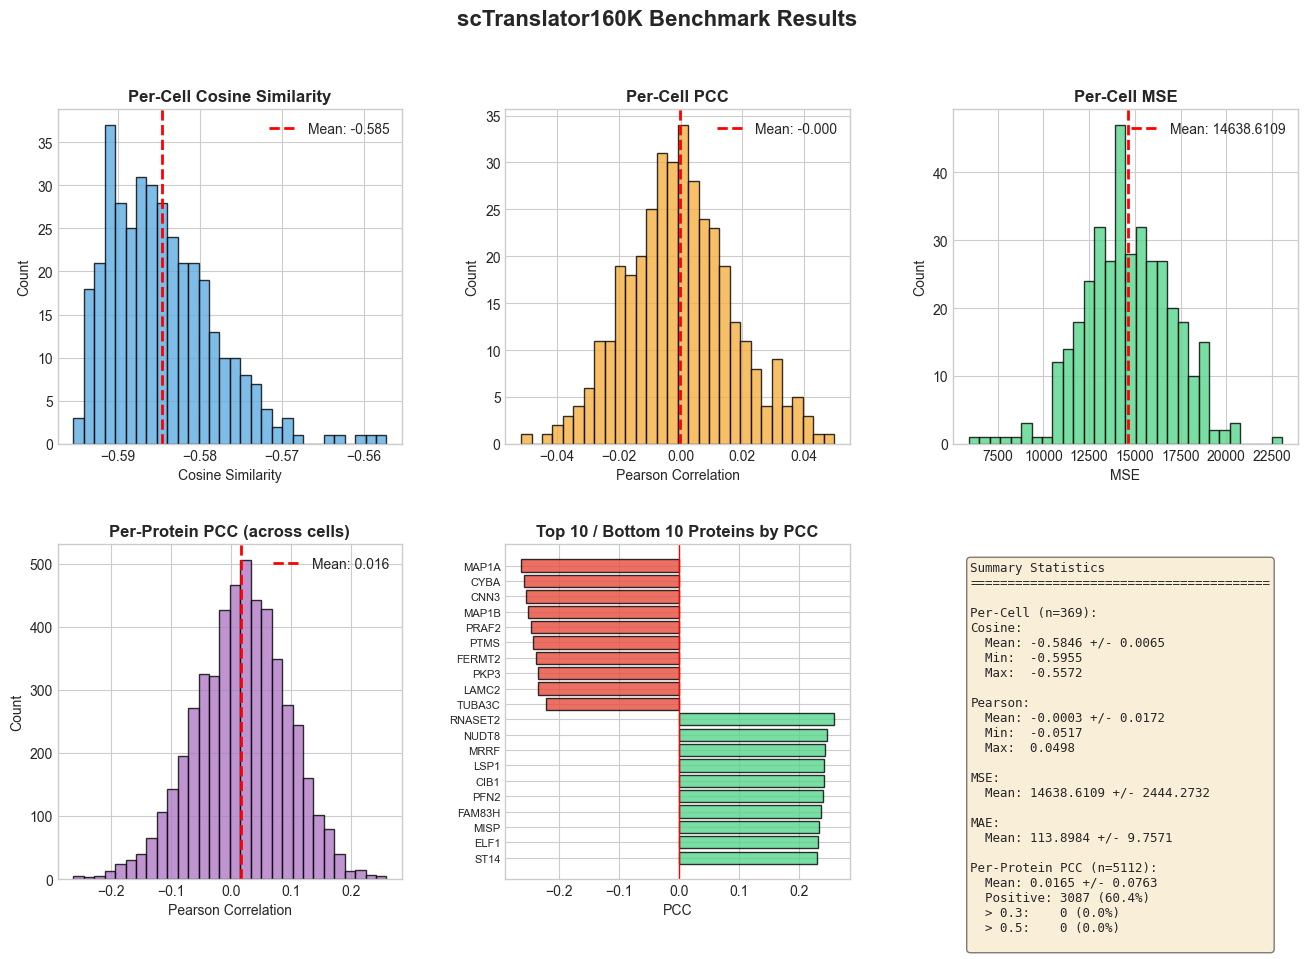

In [58]:
per_cell_160k, per_protein_160k, top10_160k, bottom10_160k = compute_detailed_tables(GT_scaled, pred_df_160k)

print("160k detailed tables:")
print("  cells   :", len(per_cell_160k))
print("  proteins:", len(per_protein_160k))

display(per_cell_160k.head())
display(per_protein_160k.head(10))
plot_detailed(
    per_cell_160k,
    per_protein_160k,
    top10_160k,
    bottom10_160k,
    title="scTranslator160K Benchmark Results",
    out_path=OUT_DETAILED_RAW
)


Analysis for 2M

2m detailed tables:
  cells   : 369
  proteins: 5112


,sample,cosine,pearson,mse,mae
0,22RV1_PROSTATE,0.024011,0.009213,39521.667758,146.013323
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.027029,0.013759,39176.098790,145.361246
2,769P_KIDNEY,0.021406,-0.013609,39295.078273,145.581790
3,786O_KIDNEY,0.018940,-0.022680,40857.472054,148.467450
4,8305C_THYROID,0.026366,0.014316,38170.077640,143.492483


,protein,pearson
3897,S100A14,0.332299
1238,DSC2,0.309906
2208,LAD1,0.306198
1625,GALNT3,0.287201
3210,PKP2,0.282406
2361,MAP1A,0.280365
4661,TRIM29,0.280258
1436,EVPL,0.271378
828,CLIC1,0.270203
3354,PPP2R2B,0.268949


C:\Users\hp\AppData\Local\Temp\ipykernel_12792\773615424.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


Saved: elasticnet_detailed_metrics_raw.png


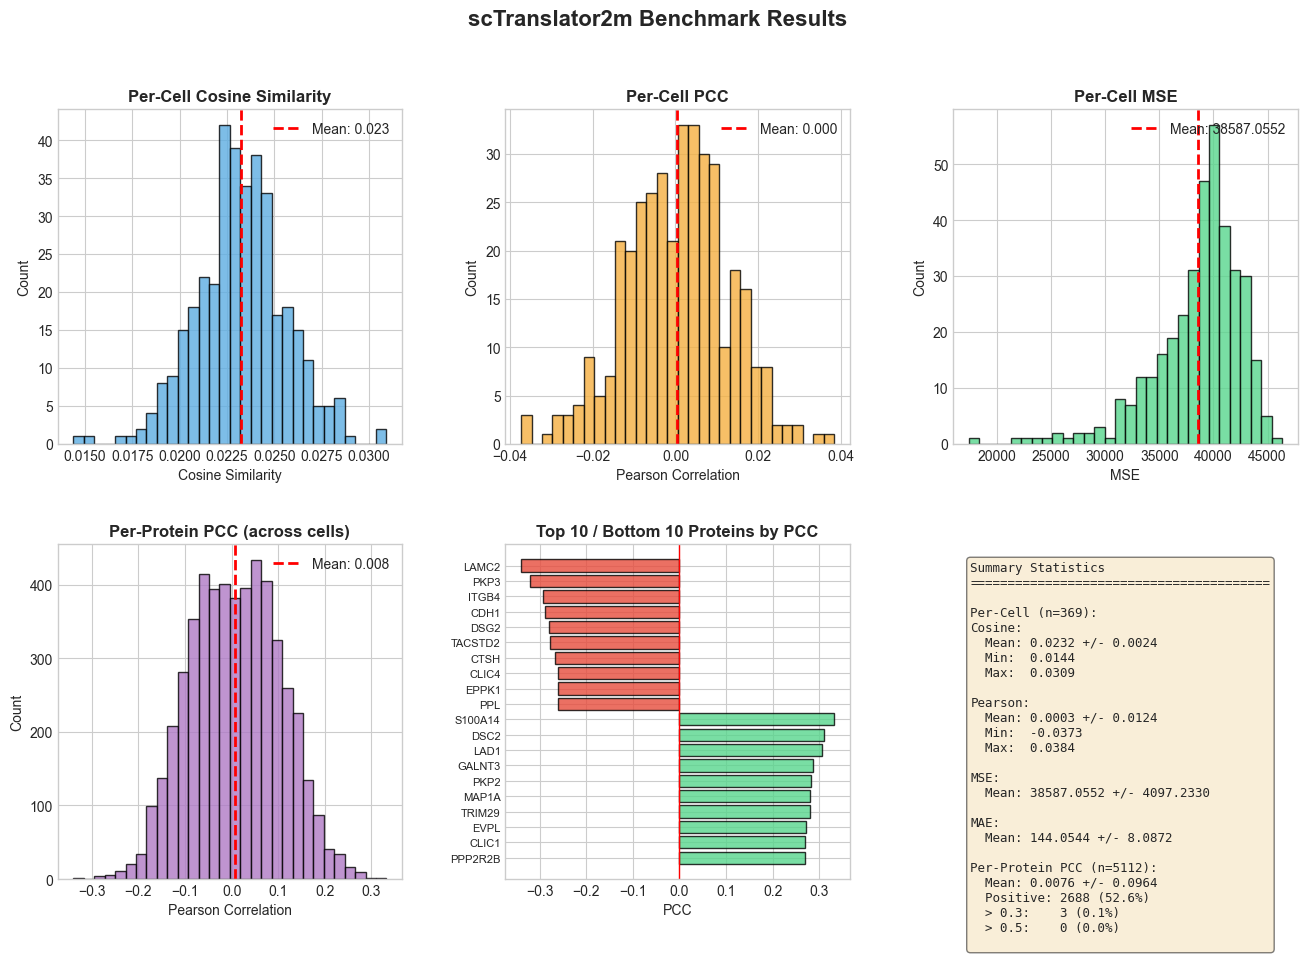

In [59]:
per_cell_2m, per_protein_2m, top10_2m, bottom10_2m = compute_detailed_tables(GT_scaled, pred_df_2m)

print("2m detailed tables:")
print("  cells   :", len(per_cell_2m))
print("  proteins:", len(per_protein_2m))

display(per_cell_2m.head())
display(per_protein_2m.head(10))
plot_detailed(
    per_cell_2m,
    per_protein_2m,
    top10_2m,
    bottom10_2m,
    title="scTranslator2m Benchmark Results",
    out_path=OUT_DETAILED_RAW
)


## Comparison Statistics between the different models predictions:


Below we try and dig deeper into what the distributions of the models predictions look like focusing on the variance of the predictions to see if they are on the same scale or not. This analysis includes: Looking at the scatter plots of the ground truth vs prediction for the proteins and cells with the worst PCC, median PCC and highest PCC across the scTranslator models and ElasticNet. After this we look at the histograms of the standard deviation and mean across cells and across proteins of the predictions of both models. Moreover we define a metric which is a scalar value that quantifies how closely the standard deviation of the predictions resembles that of the ground truth on average across cells, called the "Variation Ratio". The "Variation Ratio" is defined as the mean of the standard deviation per cell or per protein of the predictions divided by the mean of the standard deviation per cell or per protein of the ground truth.


Below shows the scatter plot of ground truth vs predicted value for the scTranslator models. We pick the proteins and cells to show in this scatterplot by ranking them by their PCC and taking the worst, median and best

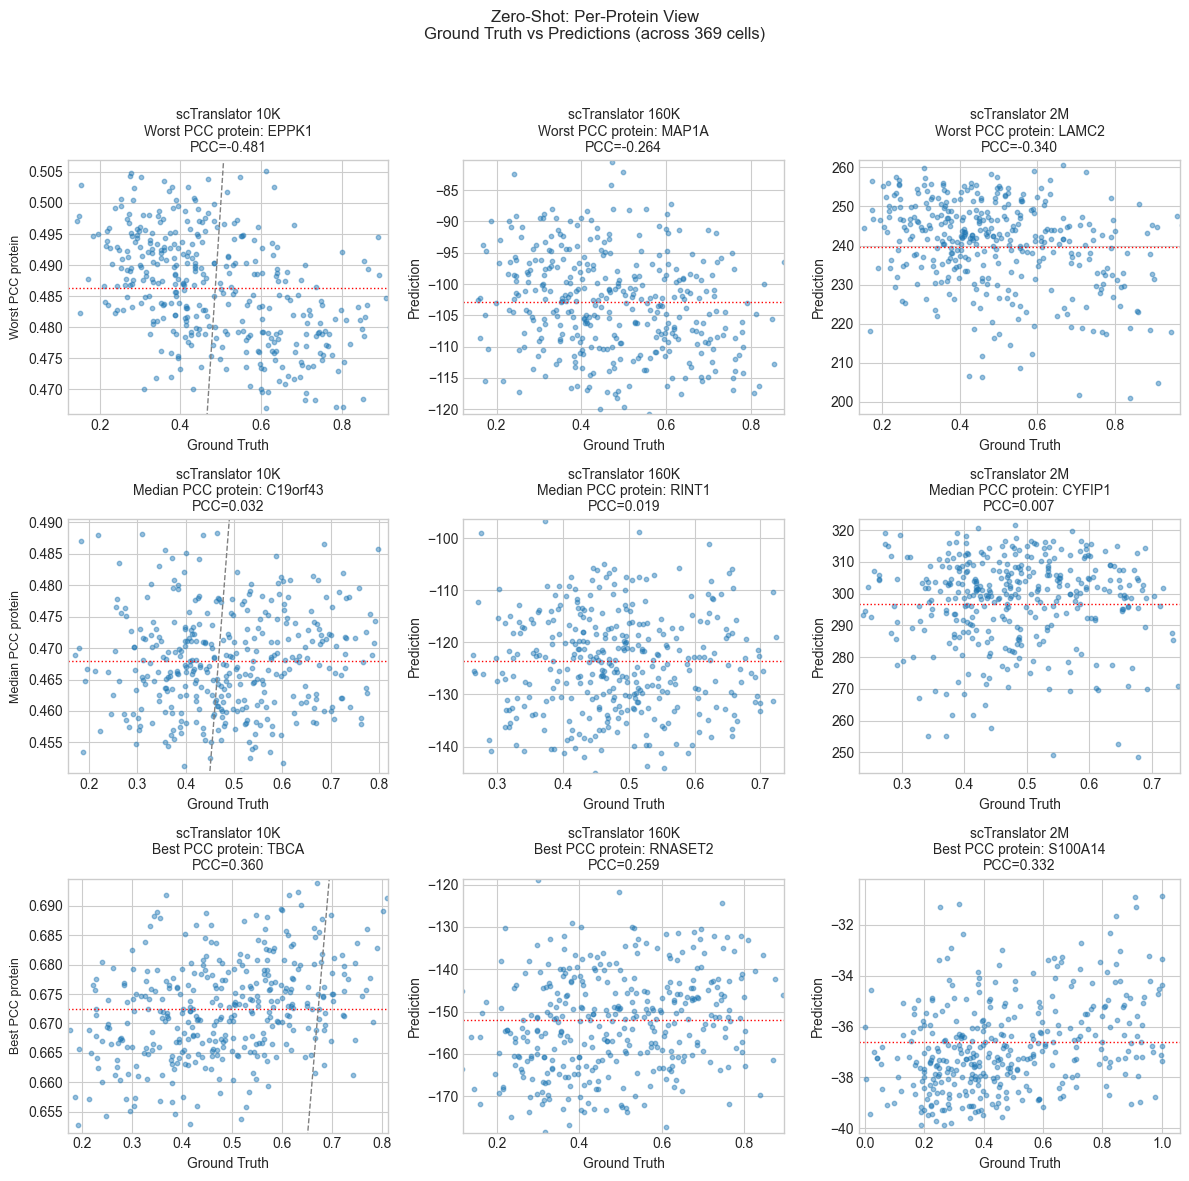

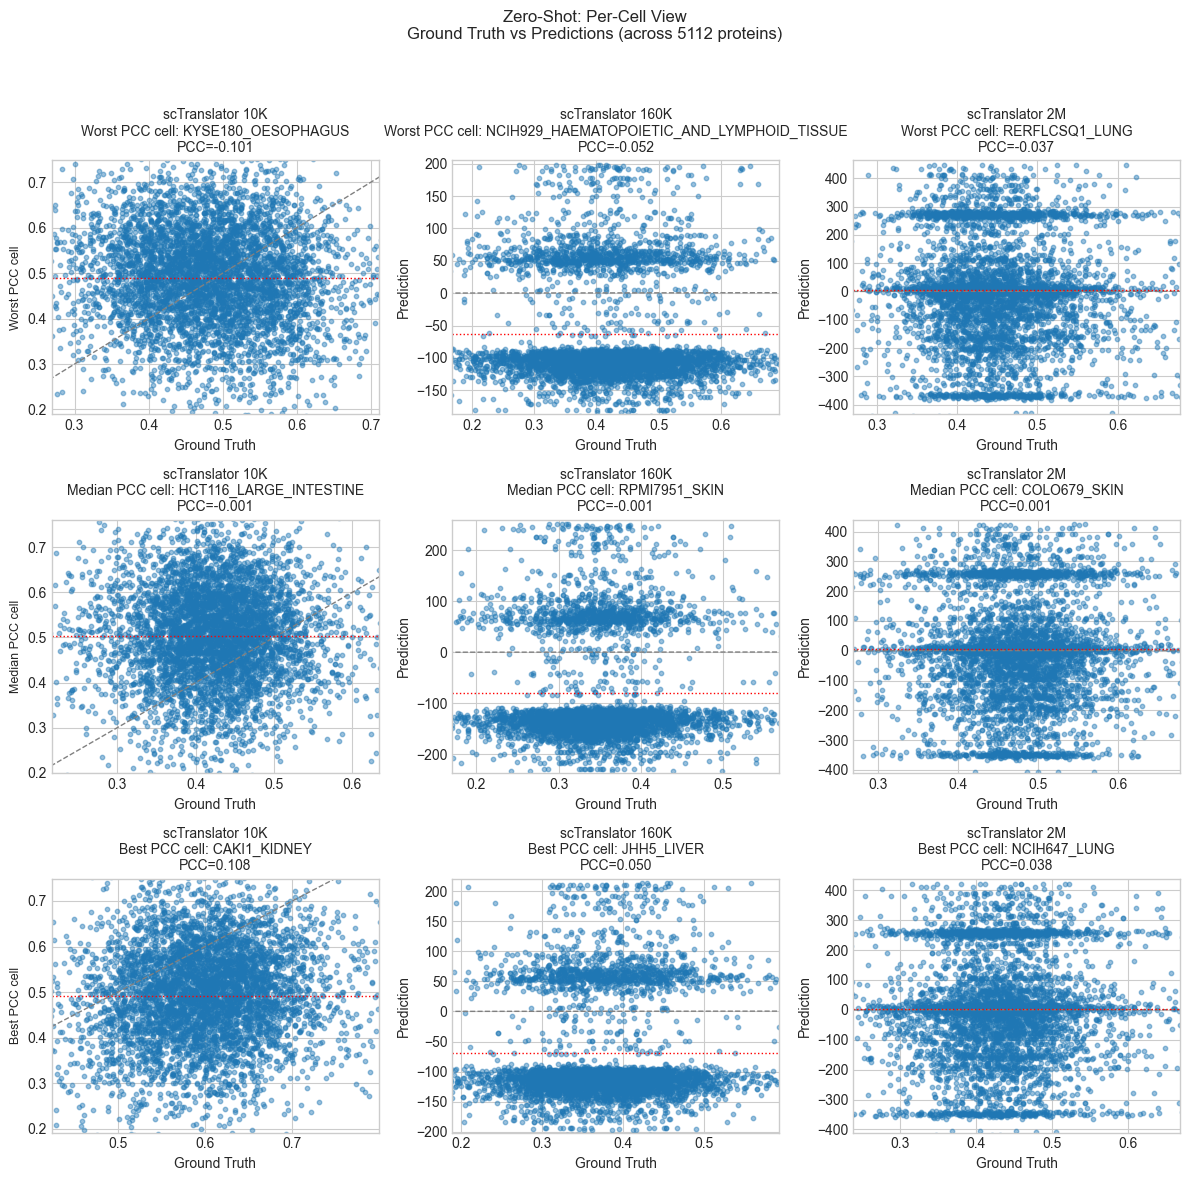

In [60]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



# ---------- helpers ----------
def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def pcc_series_rows(gt, pred):
    pcc = []
    for i in gt.index:
        y = gt.loc[i].values.astype(float)
        p = pred.loc[i].values.astype(float)
        mask = ~(np.isnan(y) | np.isnan(p))
        if mask.sum() > 1 and np.std(y[mask]) > 0 and np.std(p[mask]) > 0:
            pcc.append(pearson_correlation(y[mask], p[mask]))
        else:
            pcc.append(np.nan)
    return pd.Series(pcc, index=gt.index)

def pcc_series_cols(gt, pred):
    pcc = []
    for c in gt.columns:
        y = gt[c].values.astype(float)
        p = pred[c].values.astype(float)
        mask = ~(np.isnan(y) | np.isnan(p))
        if mask.sum() > 1 and np.std(y[mask]) > 0 and np.std(p[mask]) > 0:
            pcc.append(pearson_correlation(y[mask], p[mask]))
        else:
            pcc.append(np.nan)
    return pd.Series(pcc, index=gt.columns)

def pick_worst_median_best(pcc_series):
    s = pcc_series.dropna().sort_values()
    worst = s.index[0]
    median = s.index[len(s)//2]
    best = s.index[-1]
    return worst, median, best

def set_axes_limits(ax, x, y, quantile=0.02, pad_frac=0.08):
    x_low, x_high = np.quantile(x, [quantile, 1-quantile])
    y_low, y_high = np.quantile(y, [quantile, 1-quantile])
    xr = x_high - x_low if x_high > x_low else 1.0
    yr = y_high - y_low if y_high > y_low else 1.0
    ax.set_xlim(x_low - pad_frac*xr, x_high + pad_frac*xr)
    ax.set_ylim(y_low - pad_frac*yr, y_high + pad_frac*yr)

def scatter_panel(ax, x, y, title, pcc):
    ax.scatter(x, y, s=10, alpha=0.45)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]),
            max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, "--", color="gray", linewidth=1)
    ax.axhline(np.mean(y), color="red", linestyle=":", linewidth=1)
    ax.set_title(f"{title}\nPCC={pcc:.3f}", fontsize=10)
    ax.set_xlabel("Ground Truth")
    ax.set_ylabel("Prediction")

# ---------- data prep ----------
pred_df_10k = align_to_gt(GT_scaled, pred_df_10k)
pred_df_160k = align_to_gt(GT_scaled, pred_df_160k)
pred_df_2m = align_to_gt(GT_scaled, pred_df_2m)

models = {
    "scTranslator 10K": pred_df_10k,
    "scTranslator 160K": pred_df_160k,
    "scTranslator 2M": pred_df_2m,
}

# ---------- PER-PROTEIN ----------
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle("Zero-Shot: Per-Protein View\nGround Truth vs Predictions (across 369 cells)",
             fontsize=12, y=0.98)

row_labels = ["Worst PCC protein", "Median PCC protein", "Best PCC protein"]

for col_idx, (model_name, pred) in enumerate(models.items()):
    pcc_protein = pcc_series_cols(GT_scaled, pred)
    worst, median, best = pick_worst_median_best(pcc_protein)
    proteins = [worst, median, best]

    for row_idx, protein in enumerate(proteins):
        ax = axes[row_idx, col_idx]
        x = GT_scaled[protein].values.astype(float)
        y = pred[protein].values.astype(float)
        mask = ~(np.isnan(x) | np.isnan(y))
        x = x[mask]; y = y[mask]
        pcc = pearson_correlation(x, y) if len(x) > 1 else np.nan

        set_axes_limits(ax, x, y, quantile=0.02, pad_frac=0.08)
        label = f"{model_name}\n{row_labels[row_idx]}: {protein}"
        scatter_panel(ax, x, y, label, pcc)

        if col_idx == 0:
            ax.set_ylabel(row_labels[row_idx], fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ---------- PER-CELL ----------
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle("Zero-Shot: Per-Cell View\nGround Truth vs Predictions (across 5112 proteins)",
             fontsize=12, y=0.98)

row_labels = ["Worst PCC cell", "Median PCC cell", "Best PCC cell"]

for col_idx, (model_name, pred) in enumerate(models.items()):
    pcc_cell = pcc_series_rows(GT_scaled, pred)
    worst, median, best = pick_worst_median_best(pcc_cell)
    cells = [worst, median, best]

    for row_idx, cell in enumerate(cells):
        ax = axes[row_idx, col_idx]
        x = GT_scaled.loc[cell].values.astype(float)
        y = pred.loc[cell].values.astype(float)
        mask = ~(np.isnan(x) | np.isnan(y))
        x = x[mask]; y = y[mask]
        pcc = pearson_correlation(x, y) if len(x) > 1 else np.nan

        set_axes_limits(ax, x, y, quantile=0.02, pad_frac=0.08)
        label = f"{model_name}\n{row_labels[row_idx]}: {cell}"
        scatter_panel(ax, x, y, label, pcc)

        if col_idx == 0:
            ax.set_ylabel(row_labels[row_idx], fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Below is the same analysis for ElasticNet

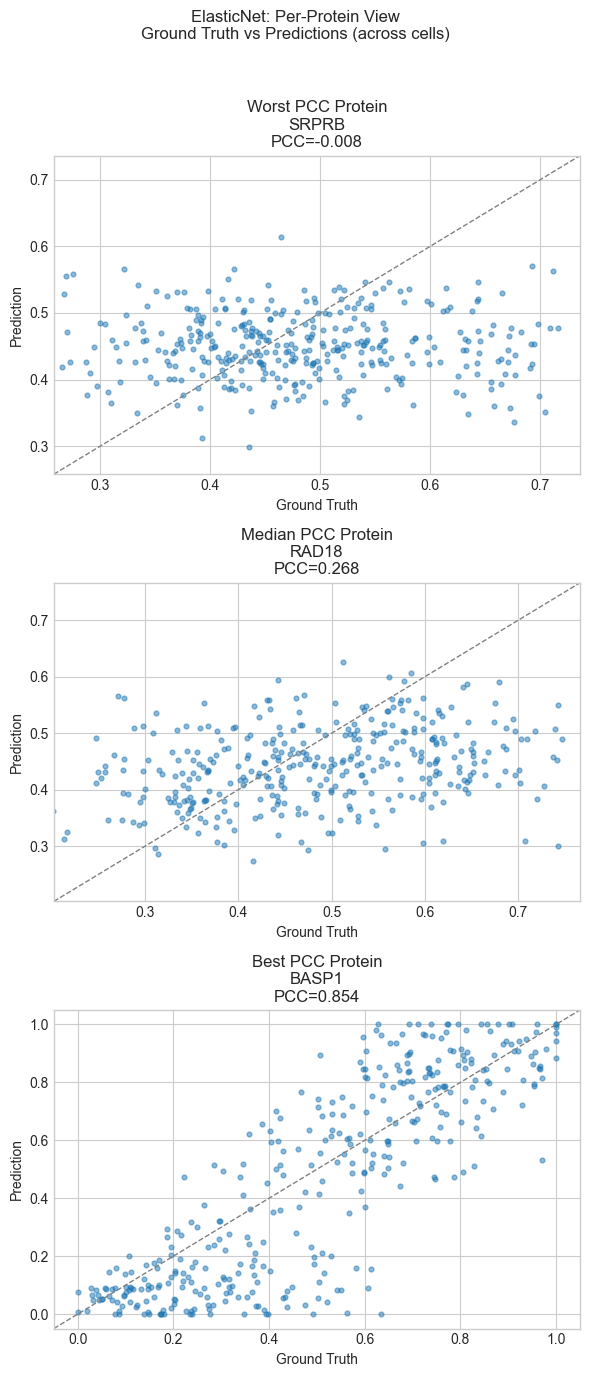

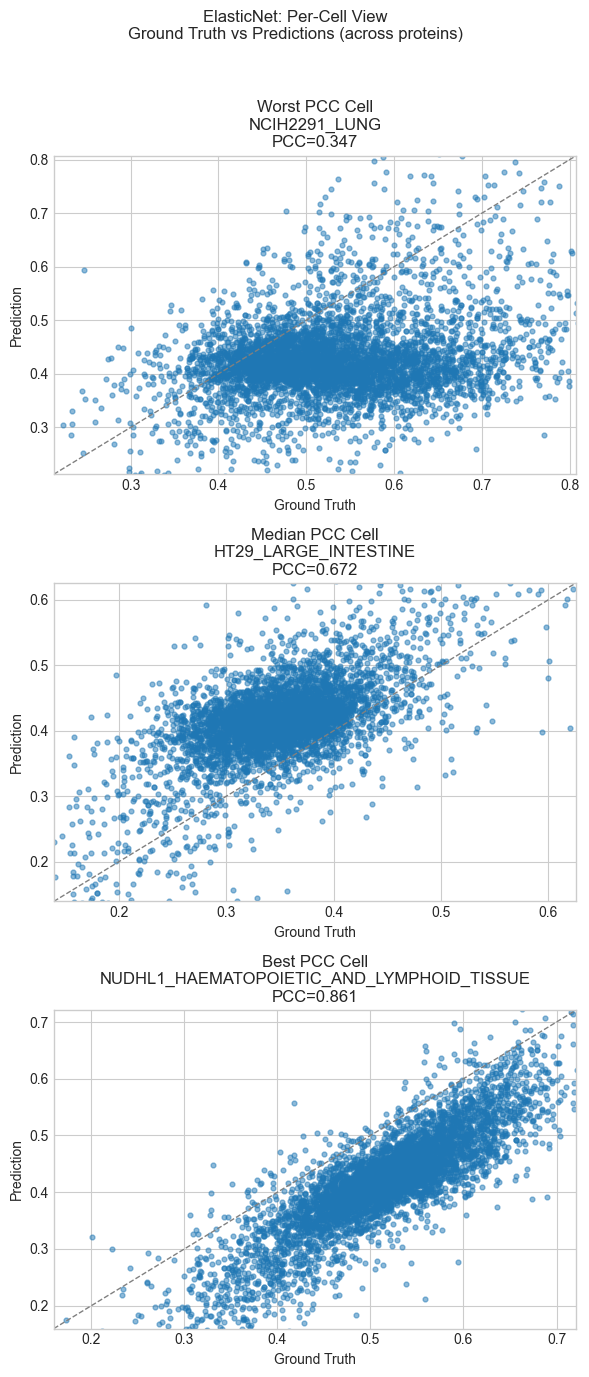

In [61]:

# ---------- align rows/cols ----------
pred_df_enet = PRED_scaled

# ---------- helpers ----------
def _robust_limits(x, y, pad=0.05):
    vals = np.concatenate([x, y])
    lo, hi = np.nanpercentile(vals, [1, 99])
    if lo == hi:
        lo, hi = np.nanmin(vals), np.nanmax(vals)
    if lo == hi:
        lo, hi = lo - 1, hi + 1
    span = hi - lo
    return lo - pad * span, hi + pad * span

def _pick_ranked_proteins(gt, pred):
    pccs = {}
    for prot in gt.columns:
        y_true = gt[prot].values.astype(float)
        y_pred = pred[prot].values.astype(float)
        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        if mask.sum() > 1:
            pccs[prot] = pearson_correlation(y_true[mask], y_pred[mask])
    s = pd.Series(pccs).dropna().sort_values()
    worst = s.index[0]
    median = s.index[len(s) // 2]
    best = s.index[-1]
    return {"worst": worst, "median": median, "best": best}, s

def _pick_ranked_cells(gt, pred):
    pccs = {}
    for cell in gt.index:
        y_true = gt.loc[cell].values.astype(float)
        y_pred = pred.loc[cell].values.astype(float)
        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        if mask.sum() > 1:
            pccs[cell] = pearson_correlation(y_true[mask], y_pred[mask])
    s = pd.Series(pccs).dropna().sort_values()
    worst = s.index[0]
    median = s.index[len(s) // 2]
    best = s.index[-1]
    return {"worst": worst, "median": median, "best": best}, s

def _scatter_panel(ax, x, y, title, pcc):
    ax.scatter(x, y, s=12, alpha=0.5)
    lims = _robust_limits(x, y)
    ax.plot(lims, lims, "--", color="gray", linewidth=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_title(f"{title}\nPCC={pcc:.3f}")
    ax.set_xlabel("Ground Truth")
    ax.set_ylabel("Prediction")

# ---------- compute ranked items ----------
prot_ranked, prot_pccs = _pick_ranked_proteins(GT_scaled, pred_df_enet)
cell_ranked, cell_pccs = _pick_ranked_cells(GT_scaled, pred_df_enet)

# ---------- PER-PROTEIN scatter ----------
fig, axes = plt.subplots(3, 1, figsize=(6, 14))
fig.suptitle("ElasticNet: Per-Protein View\nGround Truth vs Predictions (across cells)", y=0.98)

for ax, label in zip(axes, ["worst", "median", "best"]):
    prot = prot_ranked[label]
    x = GT_scaled[prot].values.astype(float)
    y = pred_df_enet[prot].values.astype(float)
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]; y = y[mask]
    _scatter_panel(ax, x, y, f"{label.capitalize()} PCC Protein\n{prot}", prot_pccs[prot])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# ---------- PER-CELL scatter ----------
fig, axes = plt.subplots(3, 1, figsize=(6, 14))
fig.suptitle("ElasticNet: Per-Cell View\nGround Truth vs Predictions (across proteins)", y=0.98)

for ax, label in zip(axes, ["worst", "median", "best"]):
    cell = cell_ranked[label]
    x = GT_scaled.loc[cell].values.astype(float)
    y = pred_df_enet.loc[cell].values.astype(float)
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]; y = y[mask]
    _scatter_panel(ax, x, y, f"{label.capitalize()} PCC Cell\n{cell}", cell_pccs[cell])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Now let's look at the distributions of the predicted values of both scTranslator and ElasticNet to see how they differ focusing on the standard deviation and mean

Below is the analysis per cell. In the plot we depict the histogram of the standard deviation per cell of the predictions and as mentioned above quanitfy how it differs from the ground truth with the Variation Ratio metric. Plotted we have the histogram of the standard deviation per cell of the ground truth and then of the four models tested and the plots of the variation ratio of the four models.

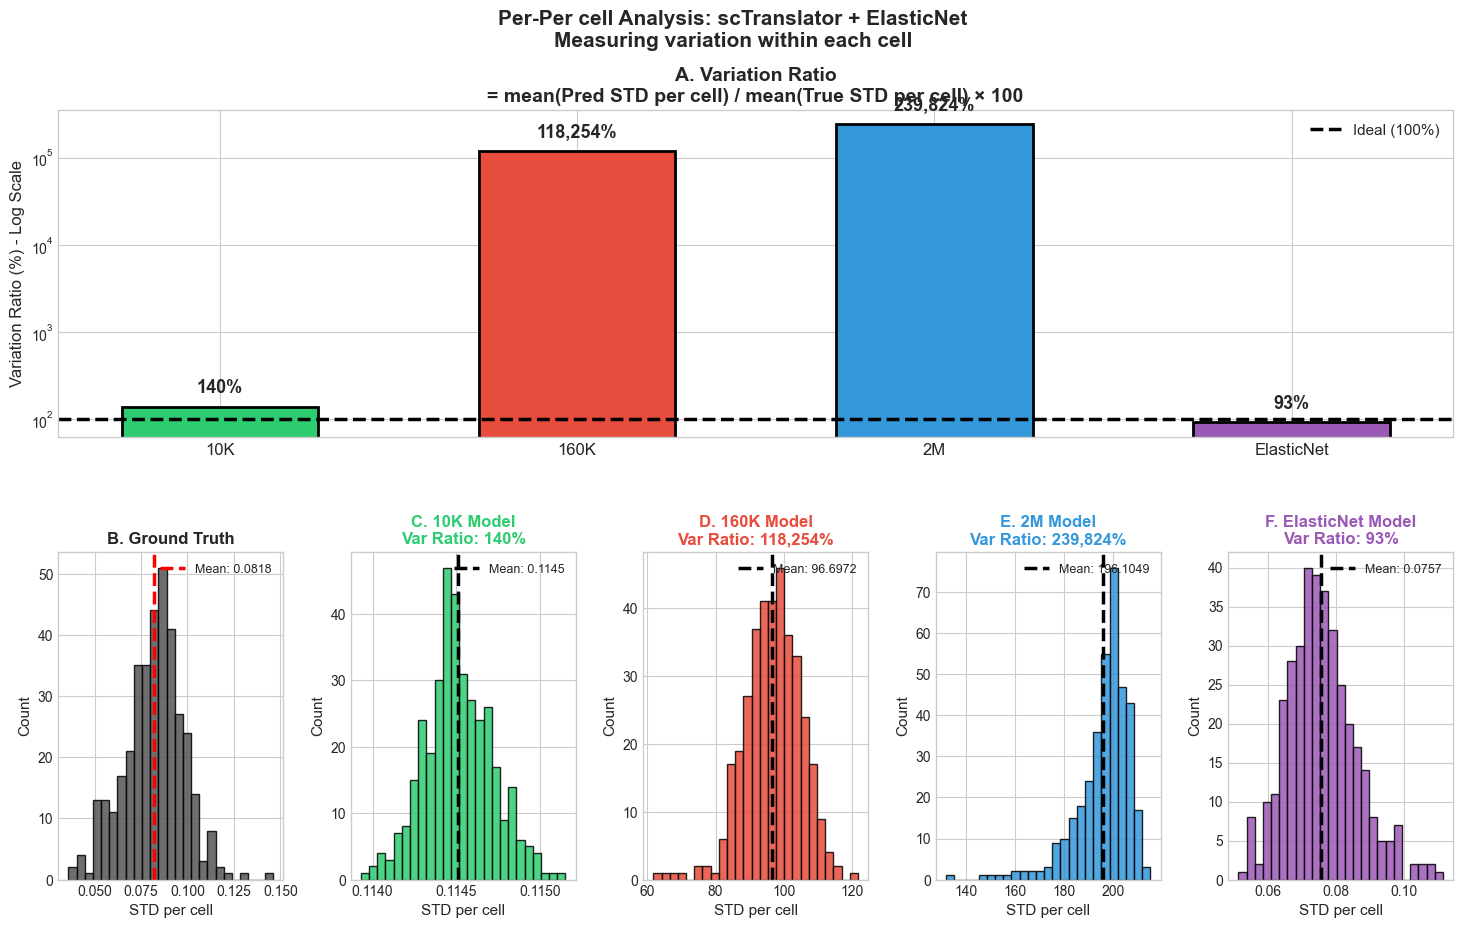

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


GT = GT_scaled
pred_10k = pred_df_10k
pred_160k = pred_df_160k
pred_2m = pred_df_2m
pred_enet = pred_df_enet  


ANALYSIS_MODE = "cell"  

# ----- helpers -----
def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def compute_stds(gt, pred, mode="cell"):
    if mode == "cell":
        true_stds = gt.std(axis=1, skipna=True)
        pred_stds = pred.std(axis=1, skipna=True)
    else:
        true_stds = gt.std(axis=0, skipna=True)
        pred_stds = pred.std(axis=0, skipna=True)
    return true_stds.values, pred_stds.values

def variation_ratio(true_stds, pred_stds):
    return (np.nanmean(pred_stds) / np.nanmean(true_stds)) * 100

# ----- align -----
pred_10k = align_to_gt(GT, pred_10k)
pred_160k = align_to_gt(GT, pred_160k)
pred_2m = align_to_gt(GT, pred_2m)
pred_enet = align_to_gt(GT, pred_enet)

models = {
    "10K": pred_10k,
    "160K": pred_160k,
    "2M": pred_2m,
    "ElasticNet": pred_enet,
}
colors = {
    "10K": "#2ECC71",
    "160K": "#E74C3C",
    "2M": "#3498DB",
    "ElasticNet": "#9B59B6",
}

# ----- compute -----
true_stds, _ = compute_stds(GT, GT, mode=ANALYSIS_MODE)
metrics = {}
for name, pred in models.items():
    _, pred_stds = compute_stds(GT, pred, mode=ANALYSIS_MODE)
    metrics[name] = {
        "pred_stds": pred_stds,
        "mean_var_ratio": variation_ratio(true_stds, pred_stds),
    }

# ----- plot -----
fig = plt.figure(figsize=(18, 10))
gs = GridSpec(2, 5, figure=fig, height_ratios=[1, 1], hspace=0.35, wspace=0.3)

# Top row: bar chart across all 4 models
ax1 = fig.add_subplot(gs[0, :])
model_names = list(models.keys())
var_ratios = [metrics[m]["mean_var_ratio"] for m in model_names]
x_pos = np.arange(len(model_names))

bars = ax1.bar(
    x_pos, var_ratios,
    color=[colors[m] for m in model_names],
    edgecolor="black", linewidth=2, width=0.55
)

ax1.axhline(y=100, color="black", linestyle="--", linewidth=2.5, label="Ideal (100%)")
ax1.set_yscale("log")
ax1.set_ylabel("Variation Ratio (%) - Log Scale", fontsize=12)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(model_names, fontsize=12)

title_suffix = "per cell" if ANALYSIS_MODE == "cell" else "per protein"
ax1.set_title(
    f"A. Variation Ratio\n= mean(Pred STD {title_suffix}) / mean(True STD {title_suffix}) × 100",
    fontsize=14, fontweight="bold"
)
ax1.legend(fontsize=11, loc="upper right")

for bar, val in zip(bars, var_ratios):
    label = f"{val:,.0f}%" if val >= 1000 else f"{val:.0f}%"
    ax1.text(bar.get_x() + bar.get_width()/2, val * 1.3, label,
             ha="center", va="bottom", fontsize=13, fontweight="bold")

# Bottom row: 5 histograms (GT + 4 models)
# Ground truth
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(true_stds, bins=25, alpha=0.85, color="#555555", edgecolor="black")
ax2.axvline(np.nanmean(true_stds), color="red", linestyle="--", linewidth=2.5,
            label=f"Mean: {np.nanmean(true_stds):.4f}")
ax2.set_xlabel(f"STD {title_suffix}", fontsize=11)
ax2.set_ylabel("Count", fontsize=11)
ax2.set_title("B. Ground Truth", fontsize=12, fontweight="bold")
ax2.legend(fontsize=9, loc="upper right")

# Each model
for i, name in enumerate(model_names, start=1):
    ax = fig.add_subplot(gs[1, i])
    pred_stds = metrics[name]["pred_stds"]
    ax.hist(pred_stds, bins=25, alpha=0.85, color=colors[name], edgecolor="black")
    ax.axvline(np.nanmean(pred_stds), color="black", linestyle="--", linewidth=2.5,
               label=f"Mean: {np.nanmean(pred_stds):.4f}")
    ax.set_xlabel(f"STD {title_suffix}", fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.set_title(f"{chr(66+i)}. {name} Model\nVar Ratio: {metrics[name]['mean_var_ratio']:,.0f}%",
                 fontsize=12, fontweight="bold", color=colors[name])
    ax.legend(fontsize=9, loc="upper right")

fig.suptitle(
    f"Per-{title_suffix.capitalize()} Analysis: scTranslator + ElasticNet\n"
    f"Measuring variation {'within each cell' if ANALYSIS_MODE=='cell' else 'across cells'}",
    fontsize=15, fontweight="bold", y=0.98
)
plt.show()

We then repeat the same analysis per protein

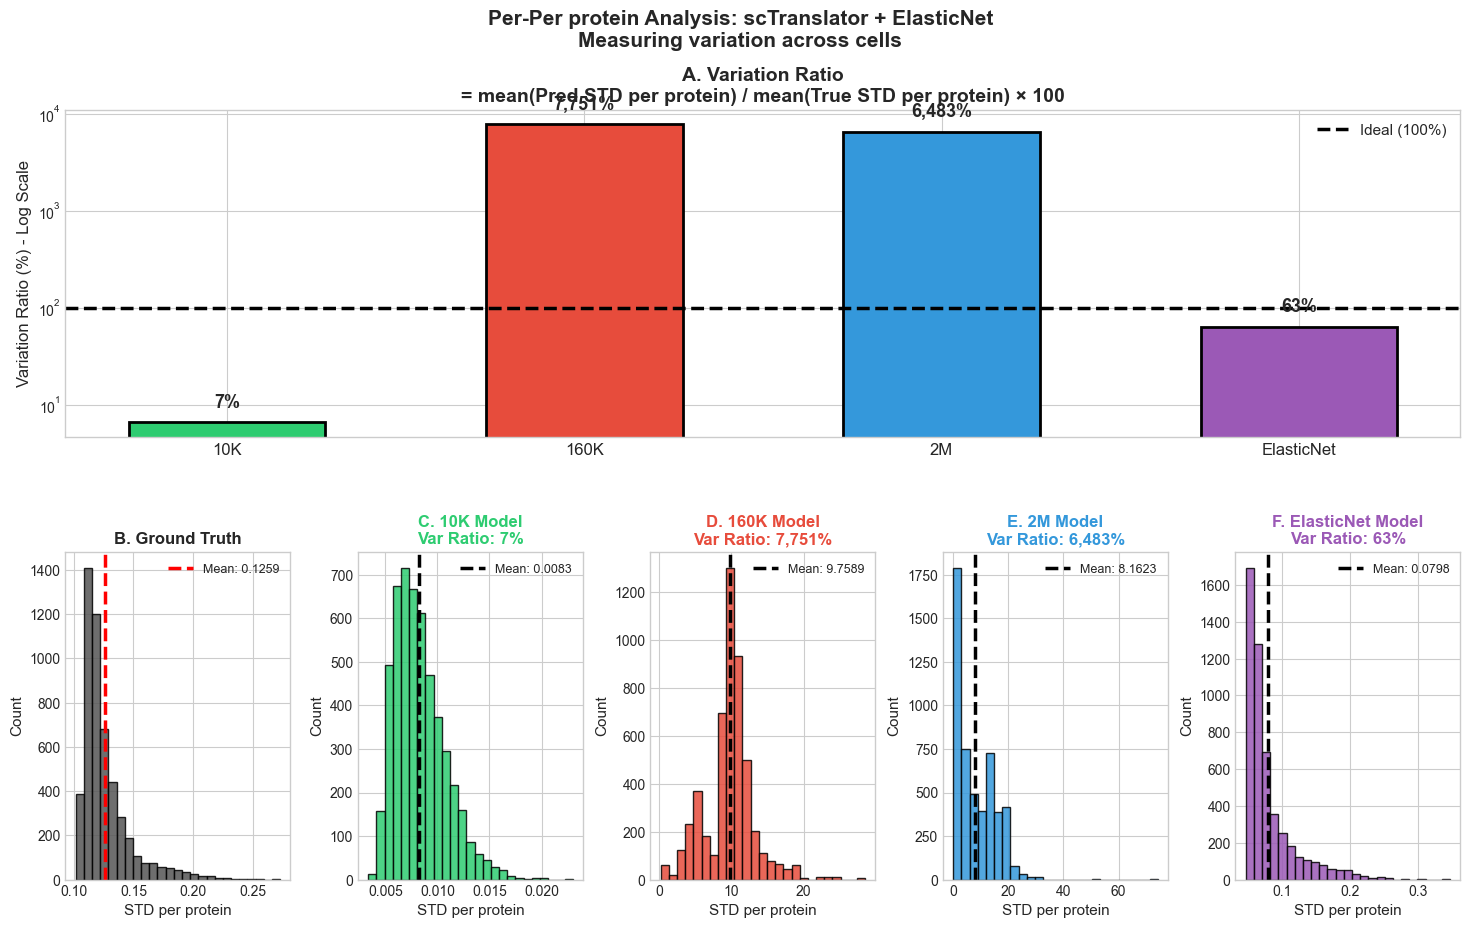

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


GT = GT_scaled
pred_10k = pred_df_10k
pred_160k = pred_df_160k
pred_2m = pred_df_2m
pred_enet = pred_df_enet  


ANALYSIS_MODE = "protein"  

# ----- helpers -----
def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def compute_stds(gt, pred, mode="cell"):
    if mode == "cell":
        true_stds = gt.std(axis=1, skipna=True)
        pred_stds = pred.std(axis=1, skipna=True)
    else:
        true_stds = gt.std(axis=0, skipna=True)
        pred_stds = pred.std(axis=0, skipna=True)
    return true_stds.values, pred_stds.values

def variation_ratio(true_stds, pred_stds):
    return (np.nanmean(pred_stds) / np.nanmean(true_stds)) * 100

# ----- align -----
pred_10k = align_to_gt(GT, pred_10k)
pred_160k = align_to_gt(GT, pred_160k)
pred_2m = align_to_gt(GT, pred_2m)
pred_enet = align_to_gt(GT, pred_enet)

models = {
    "10K": pred_10k,
    "160K": pred_160k,
    "2M": pred_2m,
    "ElasticNet": pred_enet,
}
colors = {
    "10K": "#2ECC71",
    "160K": "#E74C3C",
    "2M": "#3498DB",
    "ElasticNet": "#9B59B6",
}

# ----- compute -----
true_stds, _ = compute_stds(GT, GT, mode=ANALYSIS_MODE)
metrics = {}
for name, pred in models.items():
    _, pred_stds = compute_stds(GT, pred, mode=ANALYSIS_MODE)
    metrics[name] = {
        "pred_stds": pred_stds,
        "mean_var_ratio": variation_ratio(true_stds, pred_stds),
    }

# ----- plot -----
fig = plt.figure(figsize=(18, 10))
gs = GridSpec(2, 5, figure=fig, height_ratios=[1, 1], hspace=0.35, wspace=0.3)

# Top row: bar chart across all 4 models
ax1 = fig.add_subplot(gs[0, :])
model_names = list(models.keys())
var_ratios = [metrics[m]["mean_var_ratio"] for m in model_names]
x_pos = np.arange(len(model_names))

bars = ax1.bar(
    x_pos, var_ratios,
    color=[colors[m] for m in model_names],
    edgecolor="black", linewidth=2, width=0.55
)

ax1.axhline(y=100, color="black", linestyle="--", linewidth=2.5, label="Ideal (100%)")
ax1.set_yscale("log")
ax1.set_ylabel("Variation Ratio (%) - Log Scale", fontsize=12)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(model_names, fontsize=12)

title_suffix = "per cell" if ANALYSIS_MODE == "cell" else "per protein"
ax1.set_title(
    f"A. Variation Ratio\n= mean(Pred STD {title_suffix}) / mean(True STD {title_suffix}) × 100",
    fontsize=14, fontweight="bold"
)
ax1.legend(fontsize=11, loc="upper right")

for bar, val in zip(bars, var_ratios):
    label = f"{val:,.0f}%" if val >= 1000 else f"{val:.0f}%"
    ax1.text(bar.get_x() + bar.get_width()/2, val * 1.3, label,
             ha="center", va="bottom", fontsize=13, fontweight="bold")

# Bottom row: 5 histograms (GT + 4 models)
# Ground truth
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(true_stds, bins=25, alpha=0.85, color="#555555", edgecolor="black")
ax2.axvline(np.nanmean(true_stds), color="red", linestyle="--", linewidth=2.5,
            label=f"Mean: {np.nanmean(true_stds):.4f}")
ax2.set_xlabel(f"STD {title_suffix}", fontsize=11)
ax2.set_ylabel("Count", fontsize=11)
ax2.set_title("B. Ground Truth", fontsize=12, fontweight="bold")
ax2.legend(fontsize=9, loc="upper right")

# Each model
for i, name in enumerate(model_names, start=1):
    ax = fig.add_subplot(gs[1, i])
    pred_stds = metrics[name]["pred_stds"]
    ax.hist(pred_stds, bins=25, alpha=0.85, color=colors[name], edgecolor="black")
    ax.axvline(np.nanmean(pred_stds), color="black", linestyle="--", linewidth=2.5,
               label=f"Mean: {np.nanmean(pred_stds):.4f}")
    ax.set_xlabel(f"STD {title_suffix}", fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.set_title(f"{chr(66+i)}. {name} Model\nVar Ratio: {metrics[name]['mean_var_ratio']:,.0f}%",
                 fontsize=12, fontweight="bold", color=colors[name])
    ax.legend(fontsize=9, loc="upper right")

fig.suptitle(
    f"Per-{title_suffix.capitalize()} Analysis: scTranslator + ElasticNet\n"
    f"Measuring variation {'within each cell' if ANALYSIS_MODE=='cell' else 'across cells'}",
    fontsize=15, fontweight="bold", y=0.98
)
plt.show()

We now turn to looking at the mean of the predictions of the models per cell and per protein. We plot the histogram of the mean of the cells and protein predictions versus that of the ground truth

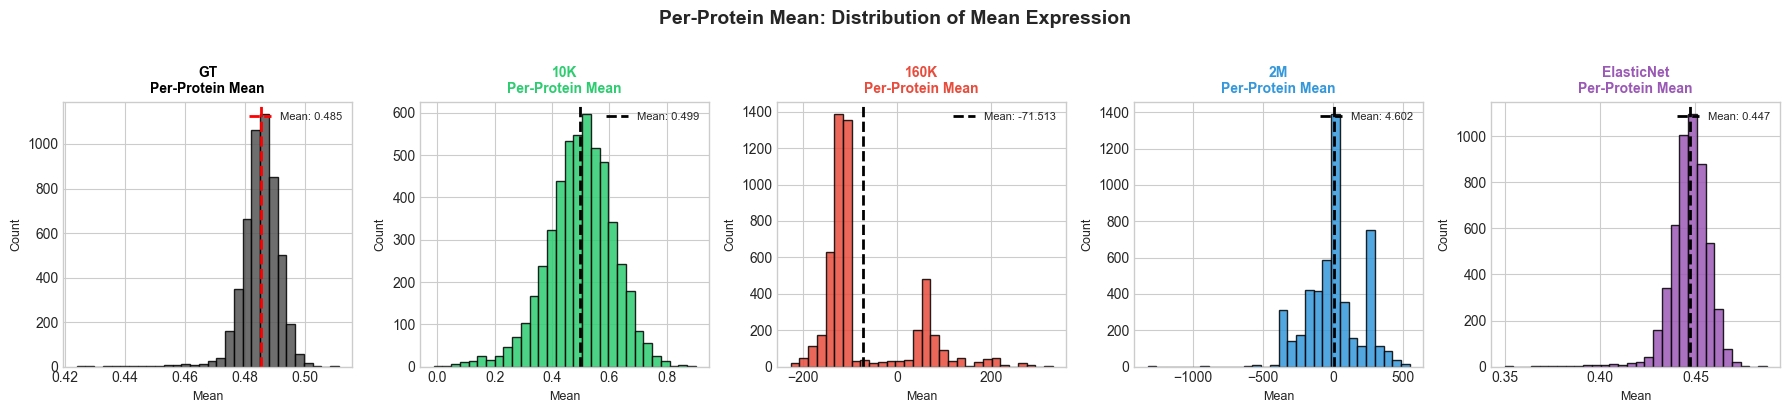

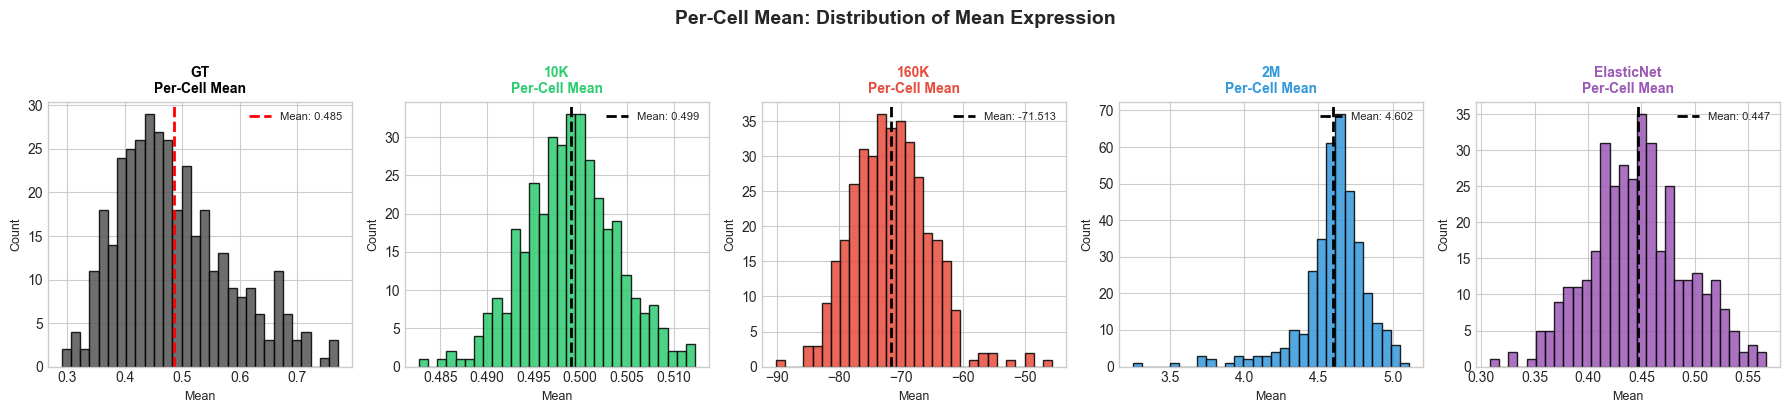

In [64]:

import numpy as np
import matplotlib.pyplot as plt

GT = GT_scaled
pred_10k = pred_df_10k
pred_160k = pred_df_160k
pred_2m = pred_df_2m
pred_enet = pred_df_enet  


def align_to_gt(gt, pred):
    return pred.reindex(index=gt.index, columns=gt.columns)

def mean_per_cell(df):
    return df.mean(axis=1, skipna=True).values

def mean_per_protein(df):
    return df.mean(axis=0, skipna=True).values

# ---------- align ----------
pred_10k = align_to_gt(GT, pred_10k)
pred_160k = align_to_gt(GT, pred_160k)
pred_2m = align_to_gt(GT, pred_2m)
pred_enet = align_to_gt(GT, pred_enet)

models = {
    "GT": GT,
    "10K": pred_10k,
    "160K": pred_160k,
    "2M": pred_2m,
    "ElasticNet": pred_enet,
}
colors = {
    "GT": "#555555",
    "10K": "#2ECC71",
    "160K": "#E74C3C",
    "2M": "#3498DB",
    "ElasticNet": "#9B59B6",
}

def plot_mean_histograms(mode="protein", bins=30):
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    title_suffix = "Per-Protein Mean" if mode == "protein" else "Per-Cell Mean"

    for ax, (name, df) in zip(axes, models.items()):
        vals = mean_per_protein(df) if mode == "protein" else mean_per_cell(df)
        ax.hist(vals, bins=bins, alpha=0.85, color=colors[name], edgecolor="black")
        ax.axvline(np.nanmean(vals), color="black" if name != "GT" else "red",
                   linestyle="--", linewidth=2, label=f"Mean: {np.nanmean(vals):.3f}")
        ax.set_title(f"{name}\n{title_suffix}", fontsize=10,
                     fontweight="bold", color=colors[name] if name != "GT" else "black")
        ax.set_xlabel("Mean", fontsize=9)
        ax.set_ylabel("Count", fontsize=9)
        ax.legend(fontsize=8, loc="upper right")

    fig.suptitle(f"{title_suffix}: Distribution of Mean Expression",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()


plot_mean_histograms(mode="protein", bins=30)
plot_mean_histograms(mode="cell", bins=30)

Additionally we now rank the best proteins according to the MSE not only to the pearson to see which proteins were able to be predicted the best based on the MSE

In [65]:

def compute_per_protein_mse(ground_truth, predictions):
    """
    Compute MSE for each protein across all samples.
    Returns a DataFrame with protein names and their MSE values.
    """
    per_protein_mse = {"protein": [], "mse": []}
    proteins = predictions.columns.tolist()
    
    for protein in proteins:
        y_true = ground_truth[protein].values.astype(float)
        y_pred = predictions[protein].values.astype(float)
        
        mask = ~(np.isnan(y_true) | np.isnan(y_pred))
        y_true_clean = y_true[mask]
        y_pred_clean = y_pred[mask]
        
        if len(y_true_clean) > 1:
            per_protein_mse["protein"].append(protein)
            per_protein_mse["mse"].append(mse(y_true_clean, y_pred_clean))
    
    return pd.DataFrame(per_protein_mse).sort_values("mse", ascending=True)

# Compute per-protein MSE for each model
mse_enet = compute_per_protein_mse(GT_scaled, PRED_scaled)
mse_10k = compute_per_protein_mse(GT_scaled, pred_df_10k)
mse_160k = compute_per_protein_mse(GT_scaled, pred_df_160k)
mse_2m = compute_per_protein_mse(GT_scaled, pred_df_2m)

# Get top 10 (lowest MSE) and bottom 10 (highest MSE) for each model
top10_mse_enet = mse_enet.head(10)
bottom10_mse_enet = mse_enet.tail(10)

top10_mse_10k = mse_10k.head(10)
bottom10_mse_10k = mse_10k.tail(10)

top10_mse_160k = mse_160k.head(10)
bottom10_mse_160k = mse_160k.tail(10)

top10_mse_2m = mse_2m.head(10)
bottom10_mse_2m = mse_2m.tail(10)

print("Per-protein MSE computed for all models:")
print(f"  ElasticNet: {len(mse_enet)} proteins")
print(f"  scTranslator 10K: {len(mse_10k)} proteins")
print(f"  scTranslator 160K: {len(mse_160k)} proteins")
print(f"  scTranslator 2M: {len(mse_2m)} proteins")

Per-protein MSE computed for all models:
  ElasticNet: 5113 proteins
  scTranslator 10K: 5112 proteins
  scTranslator 160K: 5112 proteins
  scTranslator 2M: 5112 proteins


Saved: protein_mse_ranking_comparison.png


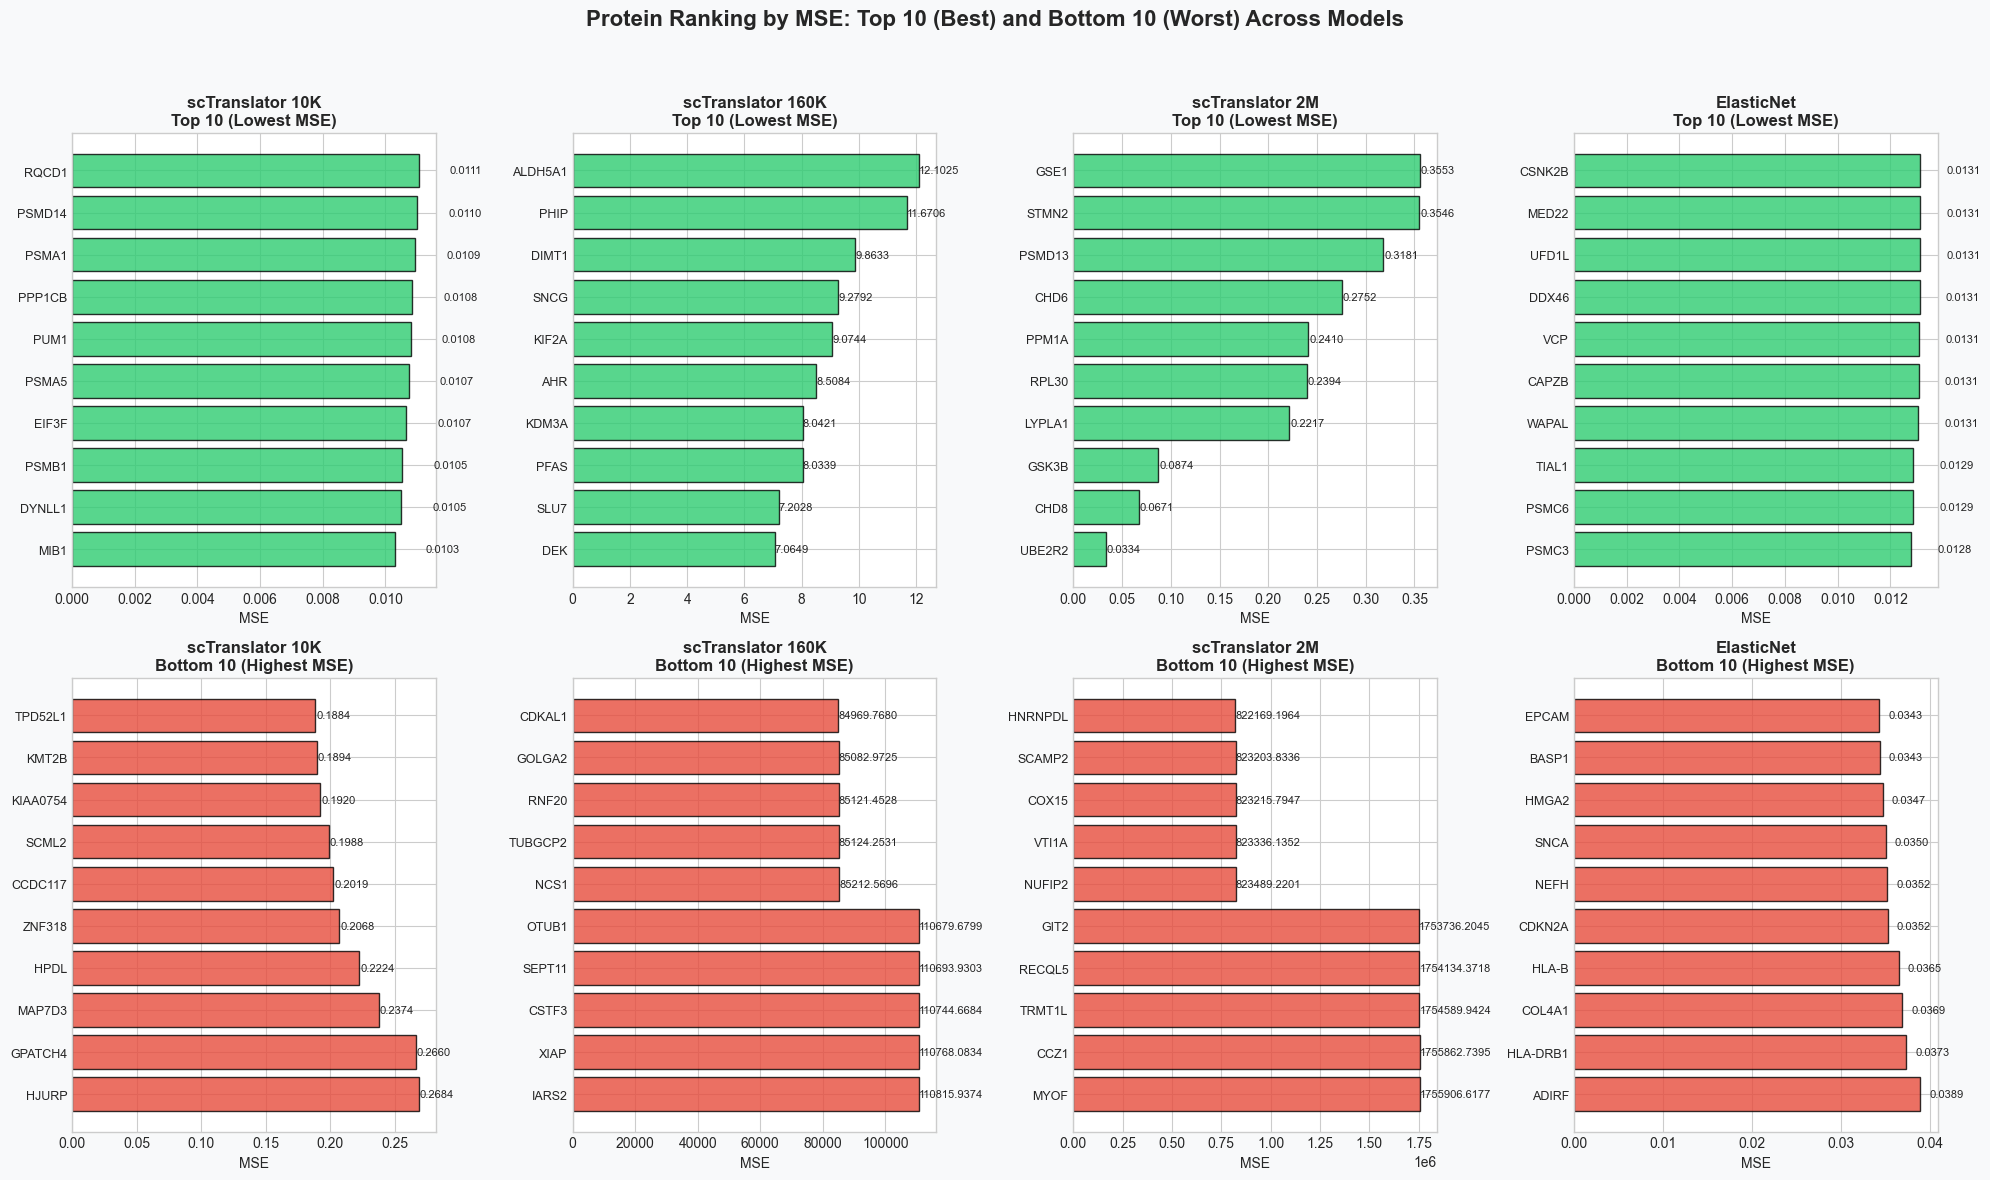


SUMMARY: Top 10 Proteins by MSE (Best Predictions)


,scT 10K,scT 10K MSE,scT 160K,scT 160K MSE,scT 2M,scT 2M MSE,ElasticNet,ENet MSE
0,MIB1,0.010292,DEK,7.064880,UBE2R2,0.033373,PSMC3,0.012790
1,DYNLL1,0.010496,SLU7,7.202769,CHD8,0.067134,PSMC6,0.012856
2,PSMB1,0.010520,PFAS,8.033880,GSK3B,0.087389,TIAL1,0.012874
3,EIF3F,0.010667,KDM3A,8.042097,LYPLA1,0.221725,WAPAL,0.013066
4,PSMA5,0.010741,AHR,8.508410,RPL30,0.239411,CAPZB,0.013068
5,PUM1,0.010804,KIF2A,9.074362,PPM1A,0.240990,VCP,0.013088
6,PPP1CB,0.010849,SNCG,9.279186,CHD6,0.275204,DDX46,0.013105
7,PSMA1,0.010950,DIMT1,9.863266,PSMD13,0.318140,UFD1L,0.013114
8,PSMD14,0.011009,PHIP,11.670559,STMN2,0.354647,MED22,0.013124
9,RQCD1,0.011058,ALDH5A1,12.102450,GSE1,0.355346,CSNK2B,0.013135



SUMMARY: Bottom 10 Proteins by MSE (Worst Predictions)


,scT 10K,scT 10K MSE,scT 160K,scT 160K MSE,scT 2M,scT 2M MSE,ElasticNet,ENet MSE
0,TPD52L1,0.188410,CDKAL1,84969.768004,HNRNPDL,8.221692e+05,EPCAM,0.034291
1,KMT2B,0.189375,GOLGA2,85082.972495,SCAMP2,8.232038e+05,BASP1,0.034336
2,KIAA0754,0.192027,RNF20,85121.452834,COX15,8.232158e+05,HMGA2,0.034662
3,SCML2,0.198772,TUBGCP2,85124.253079,VTI1A,8.233361e+05,SNCA,0.035032
4,CCDC117,0.201942,NCS1,85212.569603,NUFIP2,8.234892e+05,NEFH,0.035172
5,ZNF318,0.206816,OTUB1,110679.679880,GIT2,1.753736e+06,CDKN2A,0.035220
6,HPDL,0.222414,SEPT11,110693.930316,RECQL5,1.754134e+06,HLA-B,0.036475
7,MAP7D3,0.237379,CSTF3,110744.668358,TRMT1L,1.754590e+06,COL4A1,0.036853
8,GPATCH4,0.266039,XIAP,110768.083432,CCZ1,1.755863e+06,HLA-DRB1,0.037332
9,HJURP,0.268386,IARS2,110815.937449,MYOF,1.755907e+06,ADIRF,0.038880


In [66]:

def plot_protein_mse_comparison(model_data, title, out_path=None):
    """
    Plot top 10 (best) and bottom 10 (worst) proteins by MSE for multiple models.
    
    Parameters:
    -----------
    model_data : dict
        Dictionary with model names as keys and tuples of (top10_df, bottom10_df) as values
    title : str
        Plot title
    out_path : Path or str, optional
        Path to save the figure
    """
    n_models = len(model_data)
    fig, axes = plt.subplots(2, n_models, figsize=(5 * n_models, 12))
    fig.patch.set_facecolor("#F8F9FA")
    
    # Consistent colors: green for best (top 10), red for worst (bottom 10)
    top_color = "#2ECC71"    # Green for best performing
    bottom_color = "#E74C3C"  # Red for worst performing
    
    for col_idx, (model_name, (top10, bottom10)) in enumerate(model_data.items()):
        # Top 10 (lowest MSE - best performing) - GREEN
        ax_top = axes[0, col_idx] if n_models > 1 else axes[0]
        top10_sorted = top10.sort_values("mse", ascending=False)  # Reverse for horizontal bar
        y_pos = np.arange(len(top10_sorted))
        ax_top.barh(y_pos, top10_sorted["mse"].values, color=top_color, edgecolor="black", alpha=0.8)
        ax_top.set_yticks(y_pos)
        ax_top.set_yticklabels(top10_sorted["protein"].values, fontsize=9)
        ax_top.set_xlabel("MSE", fontsize=10)
        ax_top.set_title(f"{model_name}\nTop 10 (Lowest MSE)", fontsize=12, fontweight="bold")
        ax_top.invert_yaxis()
        
        # Add value labels
        for i, (idx, row) in enumerate(top10_sorted.iterrows()):
            ax_top.text(row["mse"] + 0.001, i, f'{row["mse"]:.4f}', va='center', fontsize=8)
        
        # Bottom 10 (highest MSE - worst performing) - RED
        ax_bottom = axes[1, col_idx] if n_models > 1 else axes[1]
        bottom10_sorted = bottom10.sort_values("mse", ascending=True)  # Reverse for horizontal bar
        y_pos = np.arange(len(bottom10_sorted))
        ax_bottom.barh(y_pos, bottom10_sorted["mse"].values, color=bottom_color, edgecolor="black", alpha=0.8)
        ax_bottom.set_yticks(y_pos)
        ax_bottom.set_yticklabels(bottom10_sorted["protein"].values, fontsize=9)
        ax_bottom.set_xlabel("MSE", fontsize=10)
        ax_bottom.set_title(f"{model_name}\nBottom 10 (Highest MSE)", fontsize=12, fontweight="bold")
        ax_bottom.invert_yaxis()
        
        # Add value labels
        for i, (idx, row) in enumerate(bottom10_sorted.iterrows()):
            ax_bottom.text(row["mse"] + 0.001, i, f'{row["mse"]:.4f}', va='center', fontsize=8)
    
    fig.suptitle(title, fontsize=16, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    if out_path:
        plt.savefig(out_path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")
    
    plt.show()

# Prepare data for plotting
model_data = {
    "scTranslator 10K": (top10_mse_10k, bottom10_mse_10k),
    "scTranslator 160K": (top10_mse_160k, bottom10_mse_160k),
    "scTranslator 2M": (top10_mse_2m, bottom10_mse_2m),
    "ElasticNet": (top10_mse_enet, bottom10_mse_enet),
}

# Plot the comparison
plot_protein_mse_comparison(
    model_data,
    title="Protein Ranking by MSE: Top 10 (Best) and Bottom 10 (Worst) Across Models",
    out_path=Path("protein_mse_ranking_comparison.png")
)

# Display summary tables
print("\n" + "="*80)
print("SUMMARY: Top 10 Proteins by MSE (Best Predictions)")
print("="*80)
summary_top = pd.DataFrame({
    "scT 10K": top10_mse_10k["protein"].values,
    "scT 10K MSE": top10_mse_10k["mse"].values,
    "scT 160K": top10_mse_160k["protein"].values,
    "scT 160K MSE": top10_mse_160k["mse"].values,
    "scT 2M": top10_mse_2m["protein"].values,
    "scT 2M MSE": top10_mse_2m["mse"].values,
    "ElasticNet": top10_mse_enet["protein"].values,
    "ENet MSE": top10_mse_enet["mse"].values,
})
display(summary_top)

print("\n" + "="*80)
print("SUMMARY: Bottom 10 Proteins by MSE (Worst Predictions)")
print("="*80)
summary_bottom = pd.DataFrame({
    "scT 10K": bottom10_mse_10k["protein"].values,
    "scT 10K MSE": bottom10_mse_10k["mse"].values,
    "scT 160K": bottom10_mse_160k["protein"].values,
    "scT 160K MSE": bottom10_mse_160k["mse"].values,
    "scT 2M": bottom10_mse_2m["protein"].values,
    "scT 2M MSE": bottom10_mse_2m["mse"].values,
    "ElasticNet": bottom10_mse_enet["protein"].values,
    "ENet MSE": bottom10_mse_enet["mse"].values,
})
display(summary_bottom)